In [ ]:
!pip -q install gdown

In [ ]:
file_id = "1HUlb13RnGtRvaqlsEj1ax43MD0llq6Yx"
url = f"https://drive.google.com/uc?id={file_id}"
!gdown --fuzzy "$url" -O data_in_valid_regions.json

Downloading...
From: https://drive.google.com/uc?id=1HUlb13RnGtRvaqlsEj1ax43MD0llq6Yx
To: /content/data_in_valid_regions.json
100% 851k/851k [00:00<00:00, 125MB/s]


In [ ]:
file_id = "1ec3WQZw4UnY_sYxx7FtY2t9aLS0pqcT7"
url = f"https://drive.google.com/uc?id={file_id}"
!gdown --fuzzy "$url" -O valid_points_data.json

Downloading...
From: https://drive.google.com/uc?id=1ec3WQZw4UnY_sYxx7FtY2t9aLS0pqcT7
To: /content/valid_points_data.json
100% 1.46M/1.46M [00:00<00:00, 114MB/s]


In [ ]:
file_id = "1RL1vNyWAPaN0YeEA2ksC5XxTsUtNj-kJ"
url = f"https://drive.google.com/uc?id={file_id}"
!gdown --fuzzy "$url" -O alpha_crossings.json

Downloading...
From: https://drive.google.com/uc?id=1RL1vNyWAPaN0YeEA2ksC5XxTsUtNj-kJ
To: /content/alpha_crossings.json
100% 678k/678k [00:00<00:00, 53.4MB/s]


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D
import seaborn as sn

from scipy.stats import qmc
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import average_precision_score, make_scorer, confusion_matrix, classification_report, accuracy_score, roc_auc_score, precision_recall_curve, auc

# Model A: learning the valid region of parameter space

The full parameter domain is

$
(a,b,c,d,e,f,\alpha)\in [0,1]^6 \times [-1,1].
$

Most parameter values in this domain produce invalid simulations, either because the trajectory blows up, produces non-finite values, or fails the numerical validity criterion.

Therefore, before studying stability or oscillation, we first need to identify regions of parameter space where valid simulations are likely.

We define Model A as a binary classifier:

$
y_A =
\begin{cases}
0, & \text{invalid}\\
1, & \text{valid}
\end{cases}
$

The goal of Model A is not to prove that a region is always valid, but to estimate

$
P_A(y=1\mid \theta)
$

and identify a region where this probability is high to sample data to train Model B, which will be used to study stability and oscillation.

# Fitting Model A

`valid_points_data.json` is stacked into a feature matrix $X_A$ with one row per simulation and seven columns $(a,b,c,d,e,f,\alpha)$, and a label vector $y_A\in\{0,1\}$. A random 20% of the rows is held out as the test set (`random_state=50`). Each simulation is treated as an independent draw, so the split is over rows rather than over groups of parameters.

The classifier is a pipeline of three pieces.

- `StandardScaler` rescales each coordinate of $\theta$ before the trees are grown.
- `HistGradientBoostingClassifier` learns the valid/invalid boundary. It uses 300 boosting iterations, learning rate $0.05$, at most 15 leaves per tree, and an $\ell_2$ penalty of $10^{-3}$.
- `CalibratedClassifierCV` fits a sigmoid map on 3-fold cross-validation so that the pipeline outputs an estimate of $P_A(y=1\mid\theta)$ rather than only a hard label.

The probability, rather than the 0/1 prediction, is what the valid-region box below is cut from.

In [ ]:
PARAM_NAMES = ["a", "b", "c", "d", "e", "f", "alpha"]

In [ ]:
data_A = pd.read_json("valid_points_data.json")
X_A = np.vstack(data_A["X"]).astype(float)
y_A = np.array(data_A["y"])

In [ ]:
X_train_A, X_test_A, y_train_A, y_test_A = train_test_split(X_A, y_A, test_size=0.2, random_state=50)

In [ ]:
base = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1e-3, random_state=0)
modelA = make_pipeline(StandardScaler(), CalibratedClassifierCV(base, method="sigmoid", cv=3))

modelA.fit(X_train_A, y_train_A)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('calibratedclassifiercv',
                 CalibratedClassifierCV(cv=3,
                                        estimator=HistGradientBoostingClassifier(l2_regularization=0.001,
                                                                                 learning_rate=0.05,
                                                                                 max_iter=300,
                                                                                 max_leaf_nodes=15,
                                                                                 random_state=0)))])

# What the Model A test results say about validity

Training accuracy is $0.95$ and test accuracy is $0.89$. The model carries most of that accuracy onto unseen parameter vectors. On the training set the predicted probabilities run from about $4.6\times 10^{-5}$ to $0.99995$. The printed training mean of $0.5$ is the average of both columns of `predict_proba`, and those two columns sum to $1$ on every row, so that mean is $0.5$ for any binary classifier. The test line is the one that describes validity: $P_A(y=1)$ runs from about $3.9\times 10^{-5}$ to $0.997$, with mean $0.24$. Scores do reach the $0.8$ threshold used to build the valid box, and the mean $0.24$ sits next to the share of the test set that is actually valid, so on average the model calls validity about as often as it occurs.

The confusion matrix is dominated by the invalid class. About $1.1\times 10^{3}$ invalid points are correctly rejected, and $58$ invalid points are called valid. Of the valid points, about $2.5\times 10^{2}$ are recovered and about $1.0\times 10^{2}$ are missed. The mistakes that would waste a later simulation are the $58$ invalid points labelled valid. The $100$ missed valid points mean the predicted valid set is smaller than the true one: Model A is conservative about declaring a parameter vector valid.

The classification report gives the same picture in rates. Accuracy is $0.89$. For the invalid class, precision, recall, and F1 are $0.91$, $0.95$, and $0.93$. For the valid class they are $0.81$, $0.71$, and $0.75$. Macro-averaged precision, recall, and F1 are $0.86$, $0.83$, and $0.84$. Accuracy sits above those macro averages because the larger invalid class, where the model is stronger, dominates the count of correct labels. The valid class is the harder one, and it is the class the sampling box depends on. A precision of $0.81$ means that a test point Model A calls valid is valid about four times in five.d recall is the share of valid points the model recovers.

In [ ]:
# training accuracy
train_acc = (modelA.predict(X_train_A) == y_train_A).mean()
print("train acc:", train_acc)

# probability spread
p_train = modelA.predict_proba(X_train_A)
print("train p(min,max,mean):", p_train.min(), p_train.max(), p_train.mean())
p_test = modelA.predict_proba(X_test_A)[:, 1]
print("test p(min,max,mean):", p_test.min(), p_test.max(), p_test.mean())

# testing accuracy
y_pred = modelA.predict(X_test_A)
accuracy = accuracy_score(y_test_A, y_pred)
print("test acc:", accuracy)

train acc: 0.9486312943562014
train p(min,max,mean): 4.5931234605099844e-05 0.9999540687653949 0.5
test p(min,max,mean): 3.883535000330461e-05 0.9968476185109464 0.23949547980823785
test acc: 0.8918918918918919


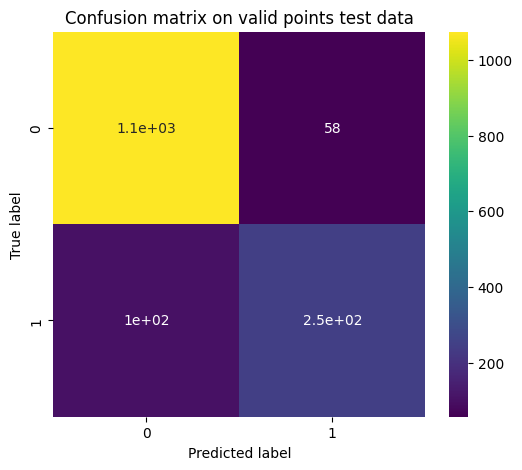

In [ ]:
y_pred = modelA.predict(X_test_A)
cm = confusion_matrix(y_test_A, y_pred)
plt.figure(figsize=(6, 5))
plt.title("Confusion matrix on valid points test data")
sn.heatmap(cm, cmap="viridis", annot=True)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()

<Axes: title={'center': 'Classification report on valid points test data'}>

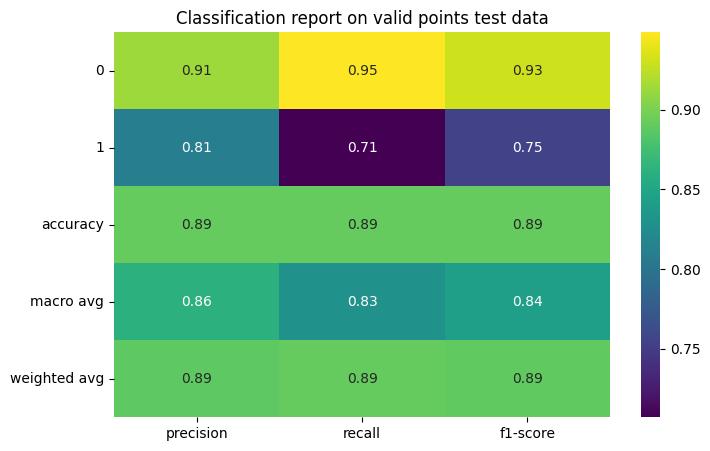

In [ ]:
cr = classification_report(y_test_A, y_pred, output_dict=True)
df_cr = pd.DataFrame(cr).T
metrics = ["precision", "recall", "f1-score"]
plt.figure(figsize=(8, 5))
plt.title("Classification report on valid points test data")
sn.heatmap(df_cr[metrics], cmap="viridis", annot=True)

In [ ]:
def plot_scatter_pairs(X, y, labels_to_plot=(0, 1)):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y)

    keep = np.isin(y, labels_to_plot)
    X1 = X[keep]
    y1 = y[keep]

    pairs = [(i, j) for i in range(7) for j in range(i+1, 7)]
    nplots = len(pairs)

    nrows, ncols = 3, 7

    cmap = ListedColormap(["tab:red", "tab:blue"])
    norm = BoundaryNorm([-0.5, 0.5, 1.5], cmap.N)

    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2*ncols, 3.8*nrows), constrained_layout=True)
    axes = axes.ravel()

    legend_elements = [Line2D([0], [0], marker="o", linestyle="", label="y = 0", markerfacecolor="tab:red", markersize=8),
                     Line2D([0], [0], marker="o", linestyle="", label="y = 1", markerfacecolor="tab:blue", markersize=8)]


    for ax, (i, j) in zip(axes, pairs):
        ax.scatter(X1[:, i], X1[:, j], c=y1, cmap=cmap, norm=norm)

        ax.set_xlim(X[:, i].min(), X[:, i].max())
        ax.set_ylim(X[:, j].min(), X[:, j].max())

        ax.legend(handles=legend_elements, title="Label")

        ax.set_xlabel(PARAM_NAMES[i])
        ax.set_ylabel(PARAM_NAMES[j])

    for ax in axes[nplots:]:
        ax.axis("off")

    fig.suptitle("Pairwise parameter scatter plots", y=1.02)
    plt.show()


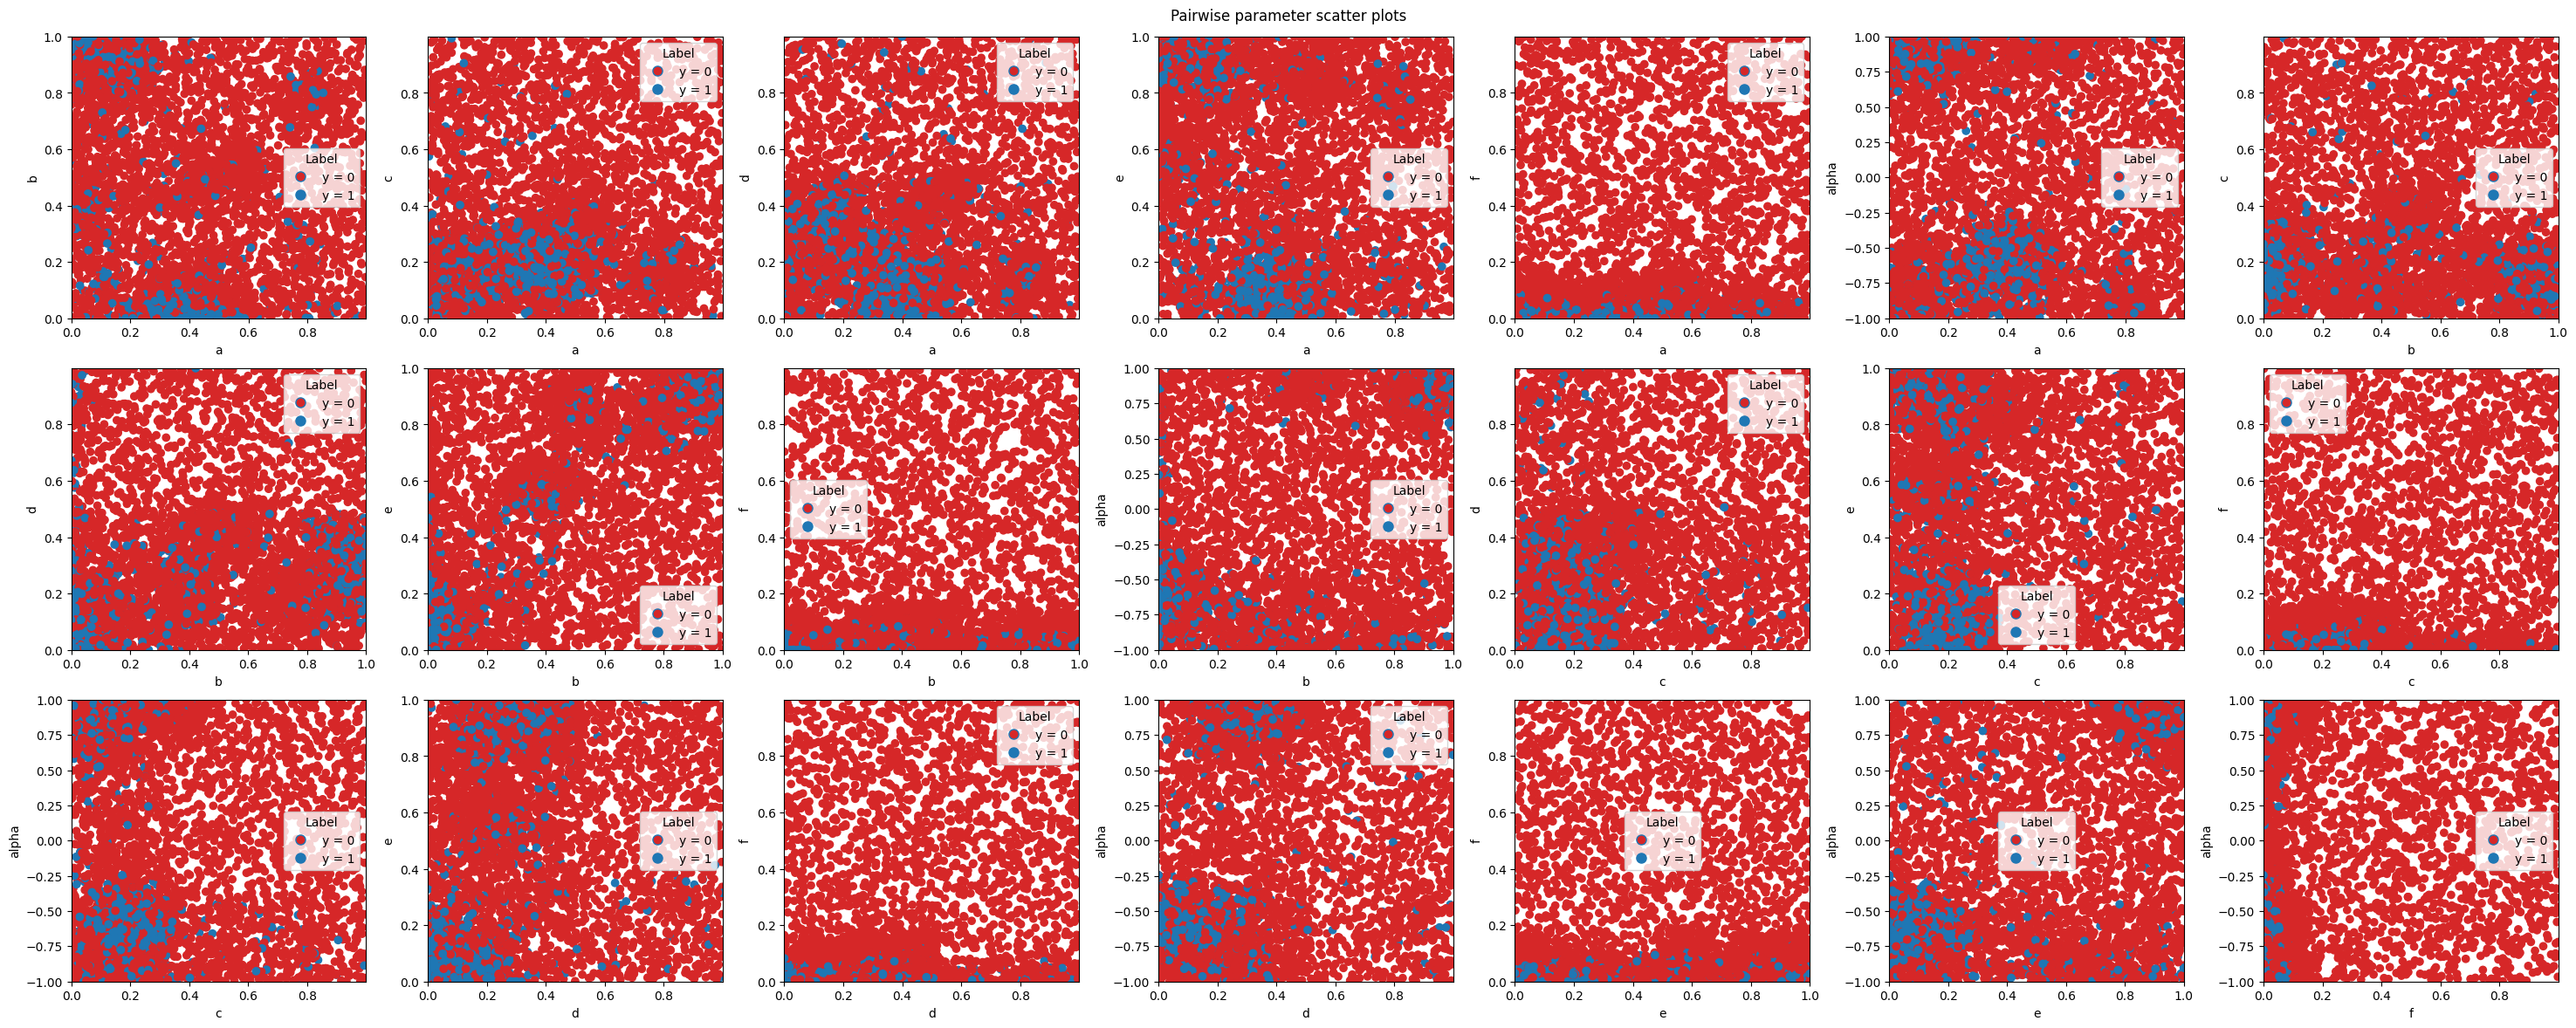

In [ ]:
plot_scatter_pairs(X_train_A, y_train_A)

In [ ]:
def plot_pca_scatter(X, y):

  pca_pipe = make_pipeline(StandardScaler(), PCA(n_components=2, random_state=0))

  X_2d = pca_pipe.fit_transform(X)

  cmap = ListedColormap(["tab:red", "tab:blue"])
  norm = BoundaryNorm([-0.5, 0.5, 1.5], cmap.N)

  fig, ax = plt.subplots(figsize=(8,6))

  scatter = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap=cmap, norm=norm, alpha=0.75)

  legend_elements = [Line2D([0], [0], marker="o", linestyle="", label="y = 0", markerfacecolor="tab:red", markersize=8),
                     Line2D([0], [0], marker="o", linestyle="", label="y = 1", markerfacecolor="tab:blue", markersize=8)]

  ax.legend(handles=legend_elements, title="Label")

  ax.set_xlabel("PC1")
  ax.set_ylabel("PC2")
  ax.set_title("PCA projection colored by label")

  plt.show()

  return X_2d, pca_pipe

### PCA projection of valid and invalid parameter sets

The figure shows the first two principal components of the sampled parameter space, with **invalid trajectories $y=0$ shown in red** and **valid trajectories $y=1$ shown in blue**.

Several observations can be made:

- The invalid samples occupy a much larger region of the projected parameter space, which is consistent with valid parameter combinations being relatively rare.
- Valid samples are not distributed uniformly. Instead, they are concentrated in several relatively compact regions, particularly at lower values of PC2.
- The projection suggests that the set of valid parameters has a structured and potentially disconnected geometry rather than forming a single simple region.
- There is substantial overlap between valid and invalid samples, especially in the central portion of the projection. Therefore, a simple linear boundary in the first two principal components would not be sufficient to reliably distinguish valid from invalid parameter combinations.
- Some regions contain a comparatively high concentration of valid samples, such as the clusters around approximately $(\mathrm{PC1}, \mathrm{PC2}) \approx (-2,\,-0.7)$ and $(2.2,-1.4)$. These regions may correspond to parameter combinations for which the system is considerably more likely to remain valid.

The PCA representation is primarily a **visualisation of the geometry of the sampled data**. Since only the first two principal components are displayed, points that overlap in this plot may still be separable along the remaining dimensions of the original seven-dimensional parameter space. Consequently, the apparent overlap should not be interpreted as showing that valid and invalid parameter sets are intrinsically inseparable.

Overall, the projection supports the use of a nonlinear classification model for identifying valid regions and suggests that valid dynamics occupy restricted, non-trivial regions of the full parameter space.

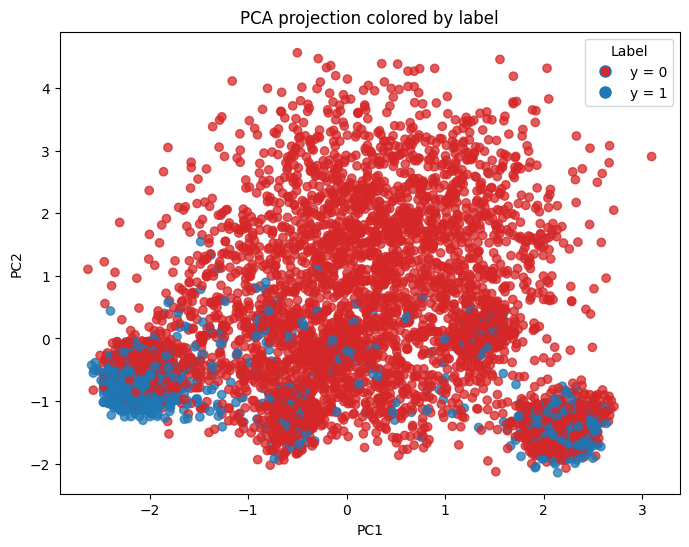

In [ ]:
X_2d, pca_pipe = plot_pca_scatter(X_train_A, y_train_A)

In [ ]:
def plot_calibration(y_true, p_class, target_class=1, n_bins=10):

    y_bin = (y_true == target_class).astype(int)

    prob_true, prob_pred = calibration_curve(
        y_bin,
        p_class,
        n_bins=n_bins,
        strategy="quantile"

    )

    plt.figure(figsize=(6, 5))
    plt.plot(prob_pred, prob_true, marker="o", label="model")
    plt.plot([0, 1], [0, 1], linestyle="--", label="perfect")
    plt.xlabel(f"Predicted P(y={target_class})")
    plt.ylabel(f"Empirical fraction y={target_class}")
    plt.title(f"Calibration for class {target_class}")
    plt.legend()
    plt.show()

### Probability calibration for valid parameter sets

The calibration curve evaluates how well the classifier's predicted probabilities for the **valid class** ($y=1$) correspond to the observed frequency of valid parameter combinations.

The dashed diagonal represents **perfect calibration**. For example, among samples assigned a predicted validity probability of $0.7$, an ideally calibrated model would produce valid trajectories approximately $70\%$ of the time.

The model's calibration curve remains close to the diagonal over most of the probability range. In particular:

- Predictions around $P(y=1)\approx0.4$, $0.7$, and $0.95$ closely match the corresponding empirical fractions of valid samples.
- The largest deviations occur at low predicted probabilities, where the number of valid samples is relatively small and the empirical estimates are therefore more sensitive to sampling variation.
- At high predicted probabilities, the model appears well calibrated; parameter combinations receiving a high predicted probability of validity are indeed valid at approximately the expected frequency.

Overall, the results suggest that the classifier probabilities contain useful information beyond the binary valid/invalid classification. This is important for subsequent parameter-space search and control, since $P(y=1)$ can potentially be used as a continuous measure of confidence that a candidate parameter combination lies within the valid region.

However, calibration is evaluated on the current test distribution. Since the dataset was partly generated using active sampling, these probabilities should not automatically be interpreted as globally calibrated probabilities over the entire parameter space without additional validation on an independently sampled dataset.

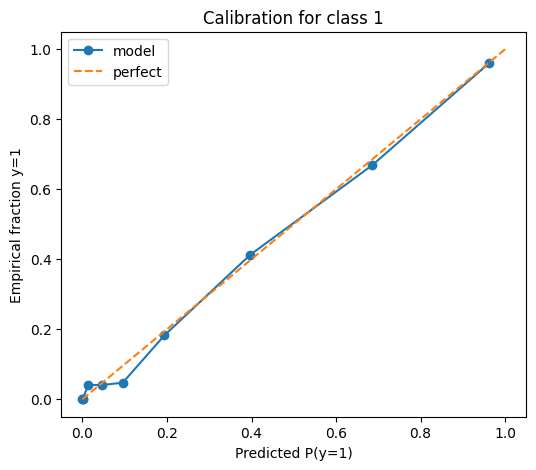

In [ ]:
probs = modelA.predict_proba(X_test_A)

target_class = 1
idx = np.where(modelA.classes_ == target_class)[0][0]

p_class = probs[:, idx]

plot_calibration(
    y_true=y_test_A,
    p_class=p_class,
    target_class=target_class,
    n_bins=10
)

### Probability calibration for invalid parameter sets

The calibration curve evaluates how well the classifier's predicted probabilities for the **invalid class** ($y=0$) correspond to the observed frequency of invalid parameter combinations.

The dashed diagonal represents **perfect calibration**. For example, if the model assigns a probability of $0.8$ to the invalid class, then approximately $80\%$ of parameter combinations receiving that probability should be invalid in a perfectly calibrated model.

The model's calibration curve follows the diagonal very closely across almost the entire probability range. In particular:

- Predictions around $P(y=0)\approx0.3$, $0.6$, and $0.8$ closely match the corresponding empirical frequencies of invalid samples.
- The high-probability region, approximately $P(y=0)\in[0.9,1.0]$, also remains close to perfect calibration, with only small deviations.
- There is no strong systematic tendency for the model to consistently overestimate or underestimate the probability of invalidity.

Overall, the classifier appears well calibrated for the invalid class. This suggests that $P(y=0)$ can be interpreted as a useful continuous measure of confidence that a candidate parameter combination will produce invalid dynamics, rather than using only the final binary classification.

This is particularly useful for later optimisation or control, where parameter combinations with high predicted invalidity could be penalised or excluded from the search space. However, because part of the dataset was generated using active sampling, calibration should ideally also be checked on an independently sampled validation set before interpreting these outputs as probabilities over the full parameter space.

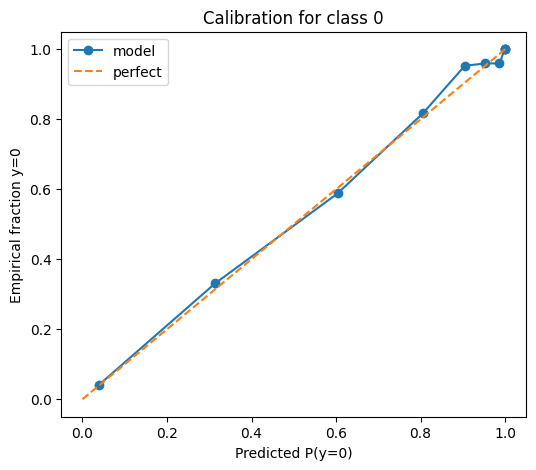

In [ ]:
probs = modelA.predict_proba(X_test_A)

target_class = 0
idx = np.where(modelA.classes_ == target_class)[0][0]

p_class = probs[:, idx]

plot_calibration(
    y_true=y_test_A,
    p_class=p_class,
    target_class=target_class,
    n_bins=10
)

### Construction of a high-probability valid parameter region

To reduce the search space for the subsequent fixed-point/oscillatory classification, Model A is used to identify parameter combinations that are likely to produce valid trajectories.

For each candidate parameter vector

$$
\theta = (a,b,c,d,e,f,\alpha),
$$

Model A returns an estimated probability

$$
P(y=1 \mid \theta),
$$

where $y=1$ denotes valid system behaviour.

Parameter combinations satisfying

$$
P(y=1 \mid \theta) \geq 0.8
$$

are retained as high-confidence valid candidates. In the current evaluation set, 170 parameter combinations satisfy this condition, with a mean predicted validity probability of approximately

$$
\overline{P(y=1)} \approx 0.946.
$$

To obtain a compact region for subsequent sampling, the lower and upper bounds of each parameter are calculated using the $5\%$ and $95\%$ marginal quantiles of the retained high-confidence points. This gives the approximate bounding box

| Parameter | Lower bound | Upper bound |
|---|---:|---:|
| $a$ | 0.0950 | 0.5018 |
| $b$ | 0.0000 | 0.8530 |
| $c$ | 0.0926 | 0.2836 |
| $d$ | 0.0000 | 0.2847 |
| $e$ | 0.0000 | 0.8674 |
| $f$ | 0.0000 | 0.0500 |
| $\alpha$ | -0.8049 | 0.9985 |

The purpose of this bounding box is to concentrate subsequent sampling on a smaller part of the original seven-dimensional parameter space in which valid behaviour is substantially more common. This is particularly useful for generating data for the second-stage model, which distinguishes stable/fixed-point dynamics from oscillatory dynamics.

Importantly, this box is only an **axis-aligned approximation** to the high-probability valid region. The valid set may have nonlinear boundaries and correlations between parameters. Consequently, a point lying inside the box is not necessarily predicted to be valid. The box should therefore be interpreted as a reduced search region rather than as a guaranteed-valid region.

In [ ]:

def sobol_sample_params(bounds, fixed=None, n_power=18, seed=None):

    bounds = np.asarray(bounds, dtype=float)

    if bounds.ndim != 2 or bounds.shape[1] != 2:
        raise ValueError(
            f"bounds must have shape (d, 2), but got {bounds.shape}"
        )

    d = bounds.shape[0]

    if fixed is None:
        fixed = {}

    fixed = {int(k): float(v) for k, v in fixed.items()}

    for dim, value in fixed.items():
        if dim < 0 or dim >= d:
            raise ValueError(f"fixed dimension {dim} outside 0..{d-1}")

        lo, hi = bounds[dim]
        if not (lo <= value <= hi):
            raise ValueError(
                f"fixed value {value} for dim {dim} outside bounds [{lo}, {hi}]"
            )

    free_dims = [i for i in range(d) if i not in fixed]

    n_samples = 2 ** n_power
    X = np.empty((n_samples, d), dtype=float)

    # Fill fixed dimensions first
    for dim, value in fixed.items():
        X[:, dim] = value

    # If no free dimensions, return repeated fixed vector
    if len(free_dims) == 0:
        return X

    sampler = qmc.Sobol(
        d=len(free_dims),
        scramble=True,
        seed=seed
    )

    U = sampler.random_base2(m=n_power)

    lower = bounds[free_dims, 0].reshape(1, -1)
    upper = bounds[free_dims, 1].reshape(1, -1)

    # Manual scaling avoids qmc.scale broadcasting issues
    X_free = lower + U * (upper - lower)

    X[:, free_dims] = X_free

    return X

In [ ]:
def likely_valid_box(model, bounds, fixed = None, test=False, p_threshold=0.8, n_power=18, q_low=0.05, q_high=0.95):

    if test:
      X_pool = X_test_A
    else:
      X_pool = X_pool = sobol_sample_params(bounds, n_power=n_power, seed=999)

    p_valid = model.predict_proba(X_pool)[:, 1]

    mask = p_valid >= p_threshold
    X_good = X_pool[mask]
    p_good = p_valid[mask]

    if len(X_good) == 0:
        return None, X_good, p_good

    box = np.column_stack([
        np.quantile(X_good, q_low, axis=0),
        np.quantile(X_good, q_high, axis=0),
    ])

    return box, X_good, p_good

In [ ]:
bounds = np.array([
    [0.0, 1.0],    # a
    [0.0, 1.0],   # b
    [0.0, 1.0],   # c
    [0.0, 1.0],   # d
    [0.0, 1.0],   # e
    [0.0, 1.0],   # f
    [-1.0, 1.0],   # alpha
])

box, X_good, p_good = likely_valid_box(
    modelA,
    bounds,
    test=True,
    p_threshold=0.8,
    n_power=18,
    q_low=0.05,
    q_high=0.95,
)

print("Number of high-probability valid points:", len(X_good))
print("Mean predicted P(valid):", np.mean(p_good))

param_names = ["a", "b", "c", "d", "e", "f", "alpha"]

if box is not None:
    for name, (lo, hi) in zip(param_names, box):
        print(f"{name}: [{lo:.6f}, {hi:.6f}]")
else:
    print("No points found with P(valid) above threshold.")

Number of high-probability valid points: 170
Mean predicted P(valid): 0.9456868366935379
a: [0.095000, 0.501761]
b: [0.000000, 0.852957]
c: [0.092554, 0.283554]
d: [0.000000, 0.284730]
e: [0.000000, 0.867380]
f: [0.000000, 0.049994]
alpha: [-0.804882, 0.998464]


### Evaluation of the reduced valid-parameter bounding box

The bounding box was evaluated by identifying test samples whose parameters lie within all seven marginal bounds.

A total of **180 test samples** fall inside the box, of which:

- **138 are valid**
- **42 are invalid**

giving an empirical validity rate of

$$
\frac{138}{180} \approx 0.767.
$$

Therefore, approximately **76.7%** of the parameter combinations inside the bounding box produce valid trajectories.

The box contains approximately **12.2%** of the full test set:

$$
\mathrm{coverage} \approx 0.122.
$$

This shows that the bounding-box procedure substantially reduces the parameter space while retaining a region in which valid dynamics are considerably more concentrated.

However, the box should not be interpreted as a guaranteed-valid region. Because it is constructed from independent marginal parameter quantiles, it does not preserve nonlinear dependencies between parameters. As a result, combinations lying inside the rectangular bounds may still correspond to invalid dynamics, as demonstrated by the 42 invalid samples found inside the box.

The bounding box is therefore best interpreted as a **reduced search region enriched in valid parameter combinations**, rather than as an exact approximation of the valid set. This reduced region can subsequently be used to make the search for fixed-point and oscillatory dynamics more computationally efficient.

In [ ]:
def evaluate_box_on_test_data(X_test, y_test, box, target_class=1):
    X_test = np.asarray(X_test, dtype=float)
    y_test = np.asarray(y_test).astype(int)

    if box is None:
        return {
            "n_test_inside_box": 0,
            "empirical_target_rate": np.nan,
            "coverage": 0.0,
            "n_target_inside_box": 0,
            "n_non_target_inside_box": 0,
        }

    mask = np.ones(len(X_test), dtype=bool)

    for j in range(X_test.shape[1]):
        lo, hi = box[j]
        mask &= (X_test[:, j] >= lo) & (X_test[:, j] <= hi)

    y_inside = y_test[mask]

    if len(y_inside) == 0:
        return {
            "n_test_inside_box": 0,
            "empirical_target_rate": np.nan,
            "coverage": 0.0,
            "n_target_inside_box": 0,
            "n_non_target_inside_box": 0,
        }

    n_target = np.sum(y_inside == target_class)
    n_non_target = len(y_inside) - n_target

    return {
        "n_test_inside_box": int(len(y_inside)),
        "empirical_target_rate": float(n_target / len(y_inside)),
        "coverage": float(np.mean(mask)),
        "n_target_inside_box": int(n_target),
        "n_non_target_inside_box": int(n_non_target),
    }

In [ ]:
box_eval = evaluate_box_on_test_data(X_test=X_test_A, y_test=y_test_A, box=box, target_class=1)

box_eval

{'n_test_inside_box': 180,
 'empirical_target_rate': 0.7666666666666667,
 'coverage': 0.12162162162162163,
 'n_target_inside_box': 138,
 'n_non_target_inside_box': 42}

# Model B: stable versus oscillatory dynamics

Model A asks only whether a simulation finishes with a finite stability score. Among the simulations that do, the score is compared with a threshold $\varepsilon$:

$
y =
\begin{cases}
0, & \text{invalid (score not finite)}\\
1, & \text{stable (score}<\varepsilon\text{)}\\
2, & \text{oscillatory (score}\ge\varepsilon\text{)}
\end{cases}
$

`data_in_valid_regions.json` is a sample taken inside the high-probability box from Model A. The counts printed next are how many of those simulations are still invalid, and the empirical valid rate inside the box. That rate is the direct check on the region Model A proposed.

Invalid rows are then removed, so Model B sees only simulations that ran. The oscillatory label is recoded from $2$ to $0$:

$
y_B =
\begin{cases}
0, & \text{oscillatory}\\
1, & \text{stable}
\end{cases}
$

$\sum(y_B)/\mathrm{len}(y_B)$ is the fraction of this sample that is stable. The rows are split 80/20 with the same random seed as Model A.

Model B is a `BalancedRandomForestClassifier` with 1500 trees, unrestricted depth, at least 3 samples in each leaf, and $\sqrt{7}$ features considered at each split. Each tree is drawn with replacement from a resample that represents the stable and oscillatory classes equally, so the forest follows both regimes when one of them is rarer in the valid box. The probability used below is $P_B(y=1\mid\theta)$, the estimated probability that a valid simulation is stable. Its complement is the estimated probability of oscillation.

In [ ]:
data_B = pd.read_json("data_in_valid_regions.json")
X_B = np.vstack(data_B["X"]).astype(float)
y_B = np.array(data_B["y"])

In [ ]:
valid_mask = (y_B == 1) | (y_B == 2)
n_total = len(y_B)
n_valid = np.sum(valid_mask)
n_invalid = np.sum(y_B == 0)

print("Total sampled inside valid box:", n_total)
print("Invalid:", n_invalid)
print("Valid:", n_valid)
print("Empirical valid rate inside box:", n_valid / n_total)

Total sampled inside valid box: 4096
Invalid: 1133
Valid: 2963
Empirical valid rate inside box: 0.723388671875


In [ ]:
indices = [i for i in range(len(y_B)) if y_B[i] == 0]
X_B = np.delete(X_B, indices, axis=0)
y_B = np.delete(y_B, indices)

In [ ]:
y_B[y_B==2] = 0

In [ ]:
sum(y_B) / len(y_B)

np.float64(0.8369895376307797)

In [ ]:
X_train_B, X_test_B, y_train_B, y_test_B = train_test_split(X_B, y_B, test_size=0.2, random_state=50)

In [ ]:
from imblearn.ensemble import BalancedRandomForestClassifier

modelB = BalancedRandomForestClassifier(
    n_estimators=1500,
    max_depth=None,
    min_samples_leaf=3,
    max_features="sqrt",
    replacement=True,
    random_state=0,
    n_jobs=-1
)

modelB.fit(X_train_B, y_train_B)

BalancedRandomForestClassifier(min_samples_leaf=3, n_estimators=1500, n_jobs=-1,
                               random_state=0)

In [ ]:
# training accuracy
train_acc = (modelB.predict(X_train_B) == y_train_B).mean()
print("train acc:", train_acc)

# probability spread
p_train = modelB.predict_proba(X_train_B)
print("train p(min,max,mean):", p_train.min(), p_train.max(), p_train.mean())
p_test = modelB.predict_proba(X_test_B)[:, 1]
print("test p(min,max,mean):", p_test.min(), p_test.max(), p_test.mean())

# testing accuracy
y_predB = modelB.predict(X_test_B)
accuracy = accuracy_score(y_test_B, y_predB)
print("test acc:", accuracy)

train acc: 0.8924050632911392
train p(min,max,mean): 0.014366666666666666 0.9856333333333333 0.5
test p(min,max,mean): 0.1054222222222222 0.981477777777778 0.6510319869375517
test acc: 0.790893760539629


### Model B evaluation: stable vs oscillatory dynamics

Model B was evaluated on valid test samples only, with the classes defined as:

- $y=0$: **oscillatory dynamics**
- $y=1$: **stable / fixed-point dynamics**

The confusion matrix is:

| Actual class | Predicted oscillatory ($0$) | Predicted stable ($1$) |
|---|---:|---:|
| Oscillatory ($0$) | 75 | 28 |
| Stable ($1$) | 96 | 390 |

The model correctly classifies

$$
75 + 390 = 465
$$

out of 589 test samples, corresponding to an overall accuracy of approximately

$$
0.79.
$$

The classification report shows that performance differs substantially between the two classes.

For the **oscillatory class** ($y=0$):

- Precision: $0.44$
- Recall: $0.73$
- F1-score: $0.55$

The recall of $0.73$ indicates that the model detects most genuinely oscillatory trajectories. However, the precision of $0.44$ is considerably lower, meaning that many trajectories predicted to be oscillatory are actually stable. This is reflected in the confusion matrix, where 96 stable trajectories are incorrectly classified as oscillatory.

For the **stable class** ($y=1$):

- Precision: $0.93$
- Recall: $0.80$
- F1-score: $0.86$

Predictions of stable behaviour are therefore considerably more reliable. A stable prediction is correct in approximately $93\%$ of cases, while approximately $80\%$ of all genuinely stable trajectories are successfully identified.

The macro-averaged and weighted scores are:

$$
\text{Macro F1} \approx 0.71,
$$

$$
\text{Weighted F1} \approx 0.81.
$$

The higher weighted score reflects both the larger number of stable samples and the stronger performance of the classifier on the stable class.

Overall, Model B identifies meaningful structure separating stable and oscillatory regions of the valid parameter space. However, the oscillatory region is less precisely identified than the stable region. The relatively high recall for oscillations makes the model useful for locating **candidate oscillatory parameter regions**, but the lower precision indicates that predicted oscillatory points should be verified through direct simulation.

For subsequent optimisation or control, the model is therefore better interpreted as a **probabilistic regime model** rather than as an exact deterministic partition of the parameter space.

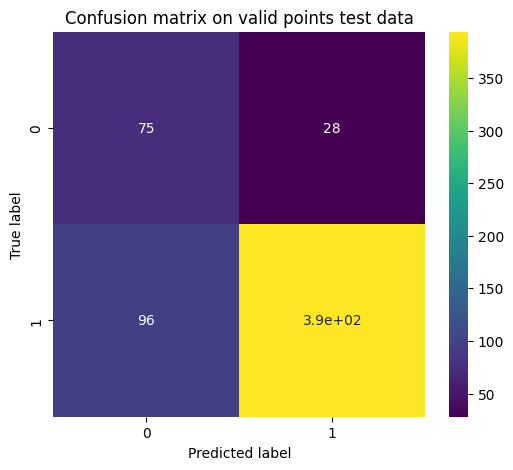

In [ ]:
y_pred = modelB.predict(X_test_B)
cm = confusion_matrix(y_test_B, y_pred)
plt.figure(figsize=(6, 5))
plt.title("Confusion matrix on valid points test data")
sn.heatmap(cm, cmap="viridis", annot=True)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()

<Axes: title={'center': 'Classification report on valid points test data'}>

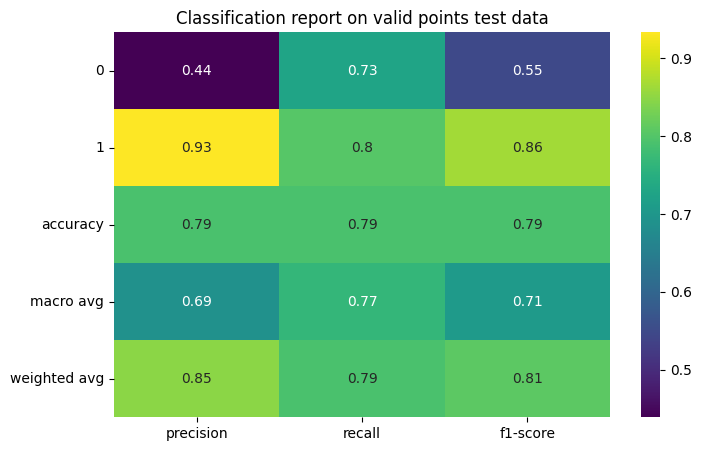

In [ ]:
cr = classification_report(y_test_B, y_pred, output_dict=True)
df_cr = pd.DataFrame(cr).T
metrics = ["precision", "recall", "f1-score"]
plt.figure(figsize=(8, 5))
plt.title("Classification report on valid points test data")
sn.heatmap(df_cr[metrics], cmap="viridis", annot=True)

### Parameter-space structure: pairwise projections and PCA

The pairwise parameter plots and PCA projection provide a visual indication of how the **oscillatory** and **stable** regimes are distributed within the valid parameter region:

- $y=0$: **oscillatory dynamics**
- $y=1$: **stable / fixed-point dynamics**

#### Pairwise parameter projections

Across most two-parameter projections, the stable and oscillatory samples show substantial overlap. No individual pair of parameters produces a simple linear or rectangular separation between the two regimes.

Several features are nevertheless visible:

- Stable trajectories occupy a broad portion of the sampled valid parameter space and are considerably more numerous than oscillatory trajectories.
- Oscillatory samples occur throughout the parameter space rather than forming one isolated cluster.
- The plots involving $\alpha$ show some of the clearest changes in class density, with oscillatory samples appearing more concentrated in particular ranges of $\alpha$. This suggests that $\alpha$ interacts with the other parameters in determining whether oscillations occur.
- Similar overlap in the remaining parameter pairs indicates that oscillatory behaviour is unlikely to be determined by a single parameter or simple pairwise threshold.

The lack of clear separation in these two-dimensional projections suggests that the dynamical regime depends on **higher-dimensional interactions between several parameters**. Consequently, identifying oscillatory regions requires a nonlinear multivariate model rather than simple parameter-wise bounds.

#### PCA projection

The PCA projection shows the seven-dimensional parameter vectors projected onto the first two principal components.

The stable and oscillatory samples again overlap strongly, with oscillatory points distributed throughout the main cloud of stable samples rather than forming a distinct PCA cluster. There is therefore no clear separation between the two dynamical regimes in the directions of greatest overall parameter variance.

This does **not** imply that the classes are intrinsically inseparable. PCA is an unsupervised linear projection designed to preserve variance in the parameter data rather than to maximize separation between dynamical labels. Relevant class structure may therefore exist in later principal components or through nonlinear combinations of the original parameters.

Overall, both visualisations indicate that the transition between stable and oscillatory behaviour has a **complex, high-dimensional structure**. This is consistent with the classification results: Model B can identify meaningful regime structure, but the oscillatory class is substantially harder to predict precisely because the two regimes do not occupy simply separable regions of parameter space.

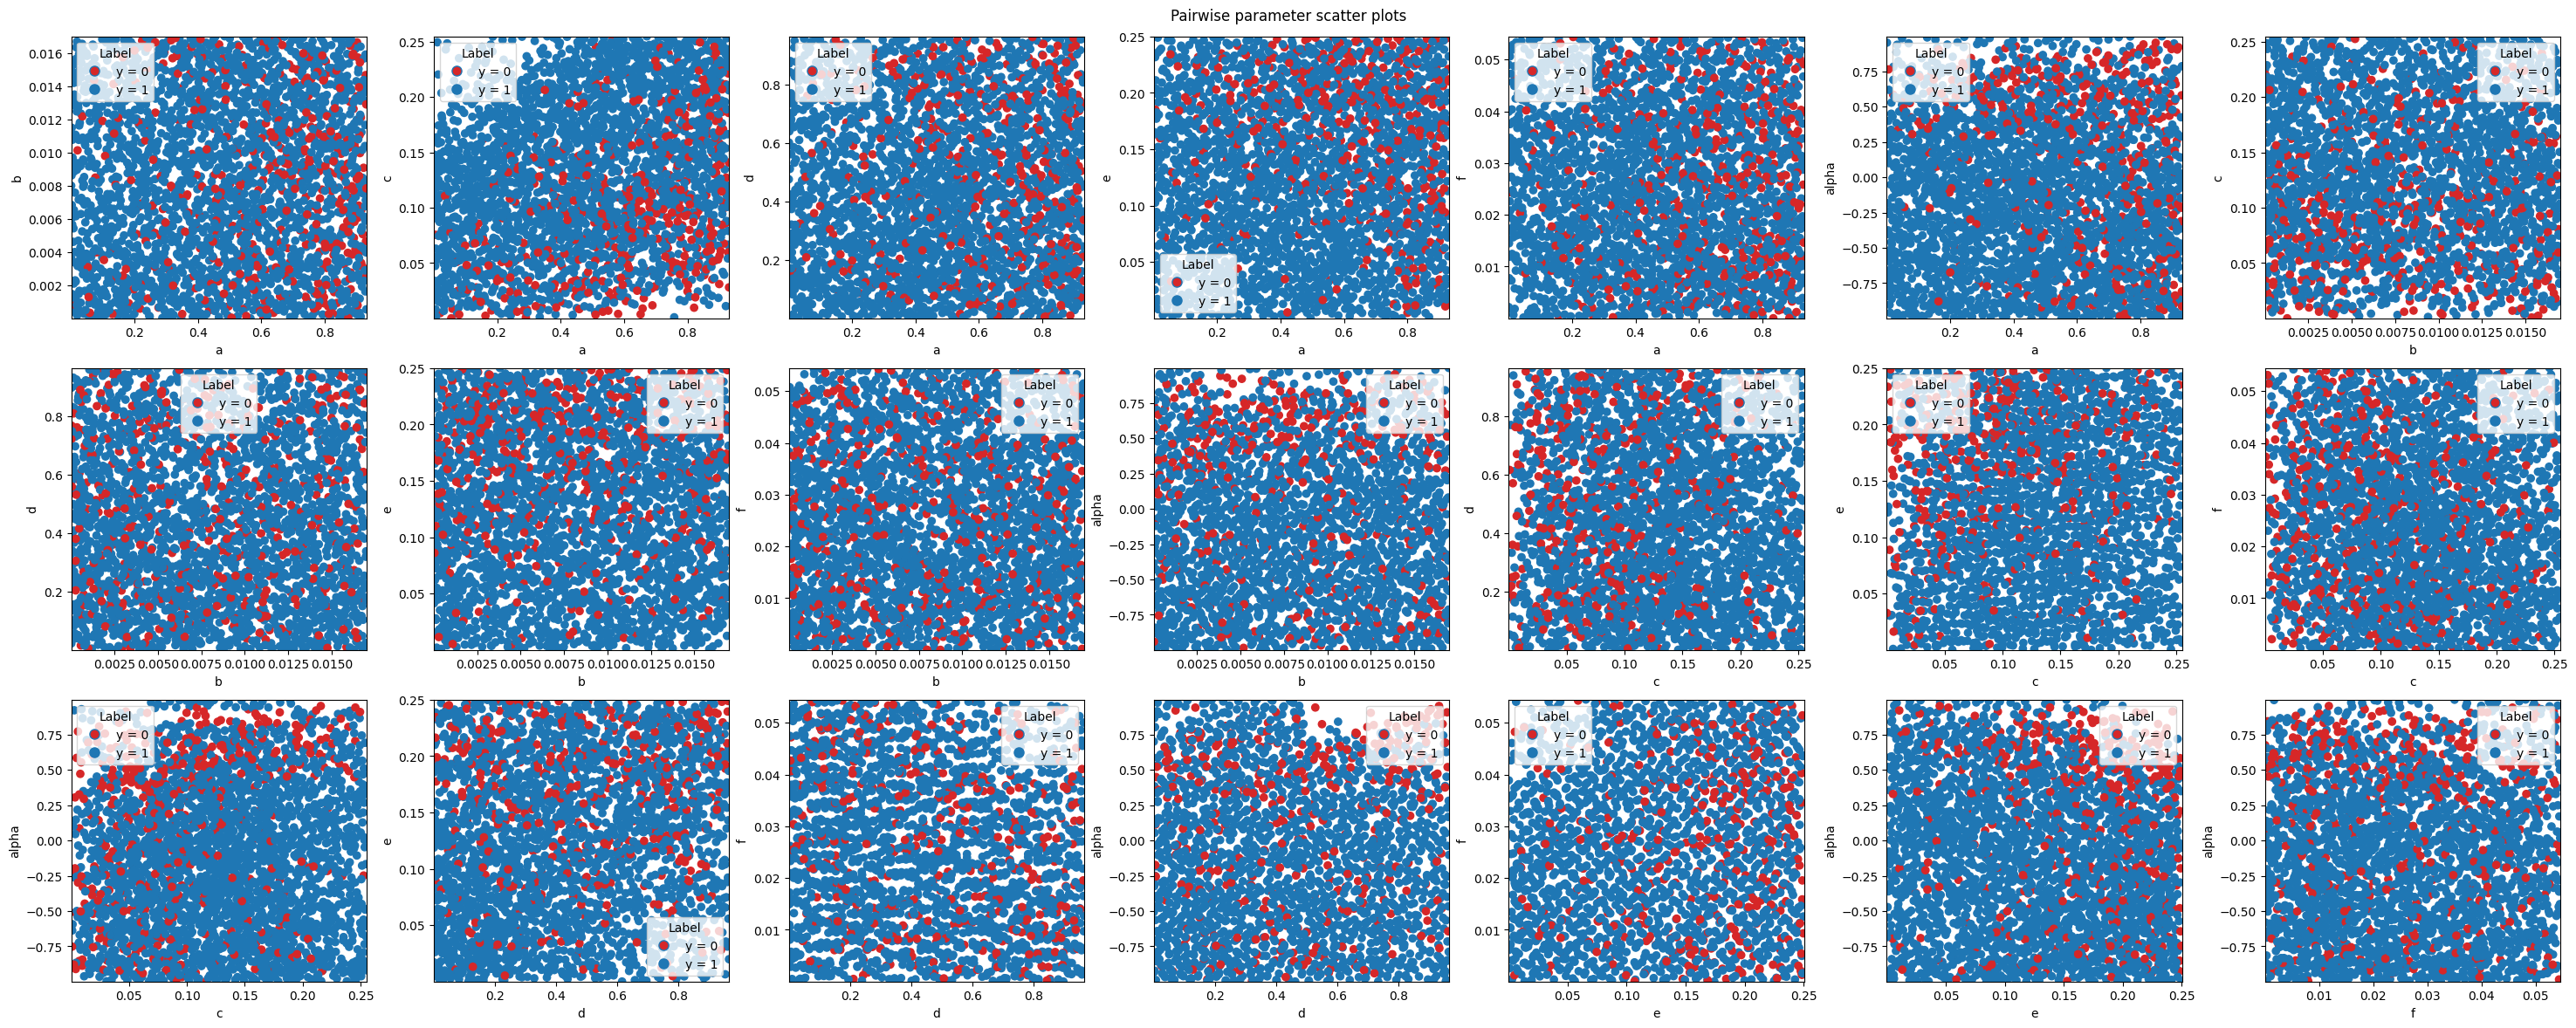

In [ ]:
plot_scatter_pairs(X_train_B, y_train_B)

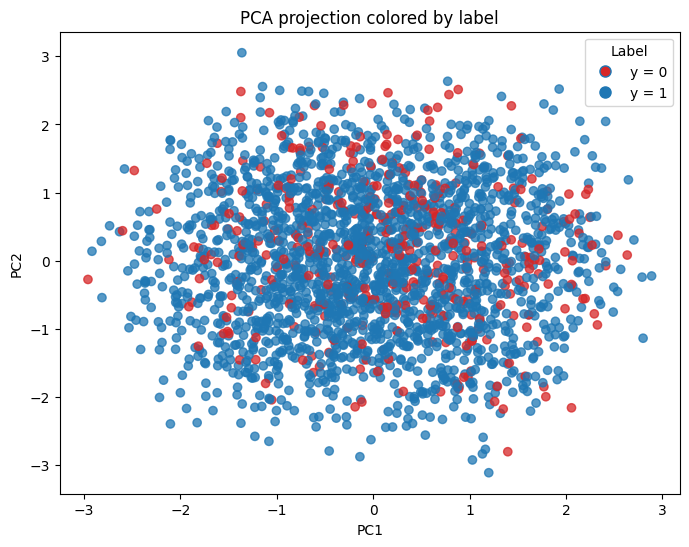

In [ ]:
X_2d, pca_pipe = plot_pca_scatter(X_train_B, y_train_B)

### Model B probability calibration and threshold analysis

The calibration curve evaluates the predicted probability of the **oscillatory class** ($y=0$). The dashed diagonal represents perfect calibration, for which a predicted probability of $p$ would correspond to an empirical oscillatory frequency of approximately $p$.

The calibration curve shows that Model B is **not uniformly calibrated for the oscillatory class**. Across much of the low-to-moderate probability range, the empirical fraction of oscillatory trajectories lies below the predicted probability. For example, predictions around $P(y=0)\approx0.5$ correspond to an empirical oscillatory frequency of only approximately $0.22$. This indicates that the model tends to **overestimate the probability of oscillatory behaviour** in this region.

Calibration improves at higher predicted probabilities. Around $P(y=0)\approx0.75$, the empirical oscillatory frequency is also approximately $0.76$, indicating substantially better calibration in the high-confidence region.

To determine whether the predicted probabilities can nevertheless be used to identify useful candidate oscillatory regions, different probability thresholds were evaluated.

| Minimum predicted $P(y=0)$ | Samples selected | Empirical oscillatory rate | Test-set coverage |
|---:|---:|---:|---:|
| $0.5$ | 171 | $43.9\%$ | $28.8\%$ |
| $0.6$ | 108 | $56.5\%$ | $18.2\%$ |
| $0.7$ | 46 | $78.3\%$ | $7.8\%$ |
| $0.8$ | 14 | $100\%$ | $2.4\%$ |
| $0.9$ | 0 | -- | $0\%$ |

At a threshold of $0.5$, the model identifies a relatively large region of the test set, but fewer than half of the selected samples are actually oscillatory. This is consistent with the relatively low precision observed for the oscillatory class in the classification report.

Increasing the threshold to $0.6$ improves the empirical oscillatory rate to approximately $56.5\%$, while reducing coverage from $28.8\%$ to $18.2\%$.

A threshold of $0.7$ produces a substantially more concentrated oscillatory region: approximately

$$
78.3\%
$$

of the selected samples are genuinely oscillatory. However, only approximately

$$
7.8\%
$$

of the test set is retained.

At a threshold of $0.8$, all 14 selected samples are oscillatory, giving an empirical rate of $100\%$. This result should be interpreted cautiously because the sample size is small and the selected region covers only approximately $2.4\%$ of the test set.

No samples receive an oscillatory probability greater than or equal to $0.9$, indicating that the classifier rarely assigns extremely high confidence to the oscillatory class.

Overall, there is a clear **precision--coverage trade-off**. Lower thresholds provide broader coverage but include many stable trajectories, whereas higher thresholds isolate progressively smaller regions that are much more strongly enriched in oscillatory dynamics. For subsequent parameter search, thresholds around $0.7$--$0.8$ may therefore be useful for identifying high-confidence candidate oscillatory regions, while direct simulation should still be used to verify the predicted regime.

The results also indicate that the raw probability estimates should not yet be interpreted as fully calibrated probabilities over the parameter space. In particular, probabilities in the moderate range tend to overestimate the empirical frequency of oscillations. If these probabilities are later used directly as costs or probabilistic constraints in MPC, additional calibration on an independent validation set would be advisable.

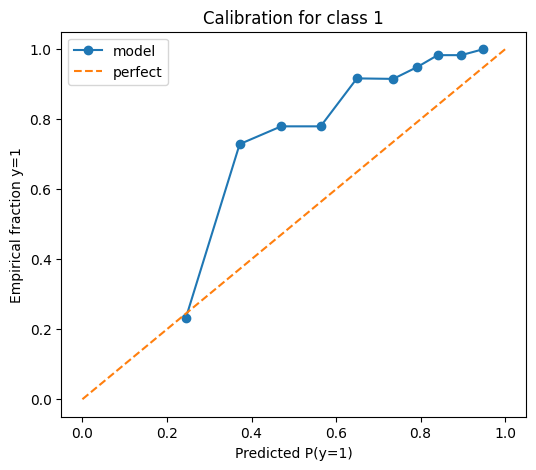

In [ ]:
probs = modelB.predict_proba(X_test_B)

target_class = 1
idx = np.where(modelB.classes_ == target_class)[0][0]

p_class = probs[:, idx]

plot_calibration(
    y_true=y_test_B,
    p_class=p_class,
    target_class=target_class,
    n_bins=10
)

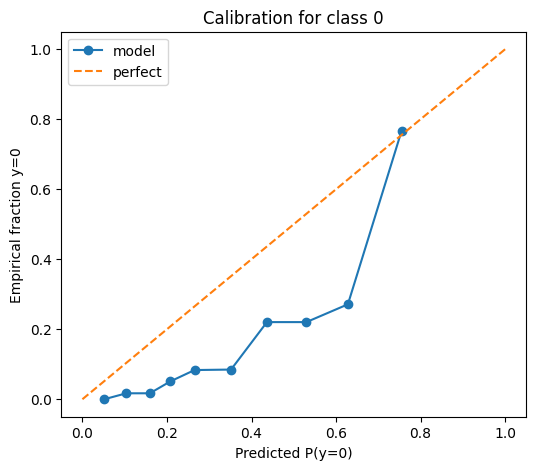

In [ ]:
target_class = 0
idx = np.where(modelB.classes_ == target_class)[0][0]

p_class = probs[:, idx]

plot_calibration(
    y_true=y_test_B,
    p_class=p_class,
    target_class=target_class,
    n_bins=10
)

In [ ]:
def high_probability_region_check(y_true, p_class, threshold=0.8, target_class=1):
    mask = p_class >= threshold

    if mask.sum() == 0:
        return {
            "threshold": threshold,
            "n_selected": 0,
            "empirical_rate": None,
            "coverage": 0.0
        }

    return {
        "threshold": threshold,
        "n_selected": int(mask.sum()),
        "empirical_rate": float(np.mean(y_true[mask] == target_class)),
        "coverage": float(np.mean(mask))
    }

In [ ]:
probs = modelB.predict_proba(X_test_B)
classes = modelB.classes_

target_class = 0
idx = np.where(classes == target_class)[0][0]
p_class = probs[:, idx]

for th in [0.5, 0.6, 0.7, 0.8, 0.9]:
    print(high_probability_region_check(
        y_test_B,
        p_class,
        threshold=th,
        target_class=target_class
    ))

{'threshold': 0.5, 'n_selected': 171, 'empirical_rate': 0.43859649122807015, 'coverage': 0.28836424957841483}
{'threshold': 0.6, 'n_selected': 108, 'empirical_rate': 0.5648148148148148, 'coverage': 0.1821247892074199}
{'threshold': 0.7, 'n_selected': 46, 'empirical_rate': 0.782608695652174, 'coverage': 0.0775716694772344}
{'threshold': 0.8, 'n_selected': 14, 'empirical_rate': 1.0, 'coverage': 0.023608768971332208}
{'threshold': 0.9, 'n_selected': 0, 'empirical_rate': None, 'coverage': 0.0}


### Identification of high-confidence stable parameter regions using clustering

To obtain a more structured description of the parameter regions associated with **stable / fixed-point dynamics** ($y=1$), Model B was evaluated on a large Sobol sample drawn from the reduced valid-parameter search space.

For each sampled parameter vector

$$
\theta = (a,b,c,d,e,f,\alpha),
$$

Model B produces an estimated probability

$$
P(y=1 \mid \theta),
$$

where $y=1$ denotes stable dynamics.

Only parameter combinations satisfying

$$
P(y=1 \mid \theta) \geq 0.8
$$

were retained. These high-confidence stable candidates were then partitioned using $K$-means clustering with six clusters. For each cluster, an axis-aligned bounding box was constructed from the $5\%$ and $95\%$ marginal quantiles of each parameter.

This procedure is intended to identify multiple distinct regions of the parameter space associated with a high predicted probability of stable behaviour, rather than representing the stable set using a single global bounding box.

A total of **88,645 high-confidence stable candidate points** were retained and divided among the six clusters.

| Cluster | Number of points | Mean $P(y=1)$ | Main $\alpha$ interval | Main $d$ interval |
|---:|---:|---:|---:|---:|
| 0 | 14,302 | 0.9026 | $[-0.980,-0.583]$ | $[0.481,0.939]$ |
| 1 | 7,813 | 0.8610 | $[0.276,0.962]$ | $[0.026,0.560]$ |
| 2 | 17,499 | 0.9005 | $[-0.338,0.214]$ | $[0.021,0.438]$ |
| 3 | 16,101 | 0.9052 | $[-0.537,-0.135]$ | $[0.447,0.936]$ |
| 4 | 18,071 | 0.9017 | $[-0.965,-0.411]$ | $[0.022,0.436]$ |
| 5 | 14,859 | 0.8938 | $[-0.084,0.368]$ | $[0.461,0.936]$ |

The remaining parameters show substantial overlap between clusters. For example, most clusters occupy broadly similar ranges of $a$, $b$, $c$, $e$, and $f$. In contrast, the largest differences between the clusters appear primarily in the values of $\alpha$ and $d$.

This suggests that the high-confidence stable region is not represented by a single compact parameter box. Instead, the classifier identifies several subregions corresponding to different combinations of the conflict parameter $\alpha$ and the Lotka--Volterra parameter $d$. In particular, the results show stable candidate regions for both negative and positive values of $\alpha$, but these regions occur together with different ranges of $d$.

All six clusters have relatively high mean predicted probabilities:

$$
0.861 \leq \overline{P(y=1)} \leq 0.905,
$$

showing that the clustering is being performed within regions that Model B already regards as strongly associated with stable dynamics.

The resulting boxes should nevertheless be interpreted as **approximate search regions rather than guaranteed stable regions**. Each box is constructed independently from marginal parameter quantiles, so combinations of parameter values lying inside a box may not themselves have $P(y=1)\geq0.8$. The boxes therefore provide a compact description of the geometry of the learned stable region and can be used to guide subsequent sampling or optimisation.

An additional limitation is that $K$-means uses Euclidean distance in the original parameter coordinates. Since the parameters have substantially different numerical ranges, clustering may be influenced more strongly by parameters with larger scales, particularly $\alpha$, $d$, and $a$. If the clusters are later used as an important part of the optimisation procedure, it would be useful to compare these results with clustering performed after standardising the free parameter dimensions.

In [ ]:
from sklearn.cluster import KMeans

def likely_class_boxes_clustered(model,
                                target_class,
                                bounds,
                                fixed=None,
                                p_threshold=0.8,
                                n_power=18,
                                n_clusters=5,
                                q_low=0.05,
                                q_high=0.95,
                                min_cluster_size=30,
                                seed=None
                                ):

    bounds = np.asarray(bounds, dtype=float)

    X_pool = sobol_sample_params(bounds=bounds, fixed=fixed,n_power=n_power, seed=seed)

    probs = model.predict_proba(X_pool)
    classes = model.classes_

    if target_class not in classes:
        raise ValueError(
            f"target_class={target_class} not found in model.classes_={classes}"
        )

    cls_idx = np.where(classes == target_class)[0][0]
    p_class = probs[:, cls_idx]

    mask = p_class >= p_threshold

    X_high = X_pool[mask]
    p_high = p_class[mask]

    if len(X_high) == 0:
        return [], X_high, p_high, X_pool, p_class


    if fixed is None:
        fixed = {}

    fixed = {int(k): float(v) for k, v in fixed.items()}
    free_dims = [i for i in range(bounds.shape[0]) if i not in fixed]

    if len(free_dims) == 0:

        box = np.column_stack([X_high[0], X_high[0]])

        boxes = [{
                "cluster": 0,
                "box": box,
                "n_points": len(X_high),
                "mean_probability": float(np.mean(p_high)),
                "min_probability": float(np.min(p_high)),
                "max_probability": float(np.max(p_high)),
                "center": X_high[0],
                "free_dims": free_dims,
                "fixed": fixed,
                }]

        return boxes, X_high, p_high, X_pool, p_class

    n_clusters_eff = min(n_clusters, len(X_high))

    kmeans = KMeans(
        n_clusters=n_clusters_eff,
        random_state=0,
        n_init="auto"
    )

    labels = kmeans.fit_predict(X_high[:, free_dims])

    boxes = []

    for k in range(n_clusters_eff):
        idx = labels == k
        Xk = X_high[idx]
        pk = p_high[idx]

        if len(Xk) < min_cluster_size:
            continue

        box = np.column_stack([
            np.quantile(Xk, q_low, axis=0),
            np.quantile(Xk, q_high, axis=0)
        ])

        for dim, value in fixed.items():
            box[dim, 0] = value
            box[dim, 1] = value

        center = np.zeros(bounds.shape[0], dtype=float)
        center[free_dims] = kmeans.cluster_centers_[k]

        for dim, value in fixed.items():
            center[dim] = value

        boxes.append({
            "cluster": k,
            "box": box,
            "n_points": int(len(Xk)),
            "mean_probability": float(np.mean(pk)),
            "min_probability": float(np.min(pk)),
            "max_probability": float(np.max(pk)),
            "center": center,
            "free_dims": free_dims,
            "fixed": fixed,
        })

    return boxes, X_high, p_high, X_pool, p_class

In [ ]:
bounds = np.array([
    [0.0, 0.931314],   # a
    [0.0, 0.017008],   # b
    [0.0, 0.254914],   # c
    [0.0, 0.964735],   # d
    [0.0, 0.250212],   # e
    [0.0, 0.054510],   # f
    [-1.0, 1.0],   # alpha
])


boxes, X_high, p_high, X_pool, p_class = likely_class_boxes_clustered(
      model=modelB,
      target_class=1,
      bounds=bounds,
      p_threshold=0.8,
      n_power=18,
      n_clusters=6,
      q_low=0.05,
      q_high=0.95,
      min_cluster_size=30,
      seed=None
)
param_names = ["a", "b", "c", "d", "e", "f", "alpha"]

for item in boxes:
  print()
  print(f"Cluster {item['cluster']}")
  print(f"n_points: {item['n_points']}")
  print(f"mean P: {item['mean_probability']:.4f}")
  for name, (lo, hi) in zip(param_names, item["box"]):
    print(f"{name}: [{lo:.4f}, {hi:.4f}]")


Cluster 0
n_points: 17491
mean P: 0.9003
a: [0.0284, 0.6613]
b: [0.0011, 0.0160]
c: [0.0527, 0.2466]
d: [0.0212, 0.4365]
e: [0.0089, 0.2236]
f: [0.0034, 0.0513]
alpha: [-0.3412, 0.2128]

Cluster 1
n_points: 16081
mean P: 0.9056
a: [0.0282, 0.6571]
b: [0.0010, 0.0160]
c: [0.0553, 0.2467]
d: [0.4477, 0.9351]
e: [0.0094, 0.2274]
f: [0.0032, 0.0514]
alpha: [-0.5331, -0.1302]

Cluster 2
n_points: 14736
mean P: 0.8938
a: [0.0262, 0.6460]
b: [0.0011, 0.0160]
c: [0.0607, 0.2472]
d: [0.4580, 0.9355]
e: [0.0083, 0.2212]
f: [0.0034, 0.0514]
alpha: [-0.0801, 0.3664]

Cluster 3
n_points: 14405
mean P: 0.9019
a: [0.0243, 0.6253]
b: [0.0010, 0.0160]
c: [0.0546, 0.2465]
d: [0.4836, 0.9387]
e: [0.0097, 0.2292]
f: [0.0031, 0.0514]
alpha: [-0.9796, -0.5808]

Cluster 4
n_points: 7921
mean P: 0.8607
a: [0.0222, 0.5750]
b: [0.0010, 0.0161]
c: [0.0965, 0.2486]
d: [0.0271, 0.5642]
e: [0.0042, 0.1328]
f: [0.0034, 0.0516]
alpha: [0.2743, 0.9620]

Cluster 5
n_points: 18098
mean P: 0.9019
a: [0.0264, 0.6456]
b: 

In [ ]:
def sample_from_cluster_box(
    model,
    cluster_item,
    target_class=1,
    p_threshold=0.8,
    max_attempts=10000,
    seed=None
):
    rng = np.random.default_rng()

    box = np.asarray(cluster_item["box"], dtype=float)

    classes = model.classes_
    cls_idx = np.where(classes == target_class)[0][0]

    for _ in range(max_attempts):

        x = rng.uniform(
            low=box[:, 0],
            high=box[:, 1]
        )

        p = model.predict_proba(x.reshape(1, -1))[0, cls_idx]

        if p >= p_threshold:
            a, b, c, d, e, f, alpha = x
            return a, b, c, d, e, f, alpha

    raise RuntimeError(
        f"No sample with P(class={target_class}) >= {p_threshold} "
        f"found after {max_attempts} attempts."
    )

In [ ]:
def lv_step(params, variables, dt=1):
    """
    Performs one step of the inner Lotka–Volterra interaction.
    Based on the first step of the complex conflict transformation p.(16)

    params: (a, b, c, d, e, f) - model parameters controlling growth and interaction rates
    variables: (p, q) - current populations of prey and predator
    dt: time step size (default 1)

    Returns:
        (p1, p2) - normalized populations after one step (stochastic form)
        z - total population used for normalization
    """

    a, b, c, d, e, f = params

    # Inner Lotka-Volterra update
    p, q = variables
    P1 = p + p*dt*(a - b*q - c*p)
    P2 = q + q*dt*(-d + e*p - f*q)

    # Normalize to obtain stochastic vector
    z = P1 + P2
    p1, p2 = P1 / z, P2 / z

    return np.array([p1, p2]), z

def combinedModel(p0, r0, alpha, params, n, dt=1):
    """
    Simulates the full conflict model combining inner Lotka–Volterra
    dynamics with outer conflict interaction between two non-annihilating systems.

    Based on the complex conflict transformation p.(16-17)

    p0, r0: initial vectors for the two systems
    alpha: conflict interaction coefficient
    params: (a, b, c, d, e, f) - Lotka–Volterra parameters
    n: total simulation time
    dt: time step size (default 1)

    Returns:
        P, R, t - arrays of population vectors and time values
    """

    # Initialize time and population lists
    t = [0.0]
    P = [np.asarray(p0, dtype=float)] # population vector of system 1
    R = [np.asarray(r0, dtype=float)] # population vector of system 2

    while t[-1] < n:

        # Apply inner Lotka-Volterra step separately to both systems.
        p, z_p = lv_step(params, P[-1], dt)
        r, z_r = lv_step(params, R[-1], dt)

        # Apply outer conflict interaction
        denom = (1 - alpha * np.inner(p, r))
        p1 = p*(1 - alpha * r) / denom
        r1 = r*(1 - alpha * p) / denom

        # Convert back to non-normalized population vectors
        P1 = p1 * z_p
        R1 = r1 * z_r

        # Add results to end of lists
        P.append(P1)
        R.append(R1)
        t.append(t[-1] + dt)

    return np.array(P), np.array(R), np.array(t)

In [ ]:
cluster_id = 3

cluster_item = next(
    item for item in boxes
    if item["cluster"] == cluster_id
)

a, b, c, d, e, f, alpha = sample_from_cluster_box(
    model=modelB,
    cluster_item=cluster_item,
    target_class=1,
    p_threshold=0.8,
    seed=42
)

print(a, b, c, d, e, f, alpha)

0.5464167204009972 0.010356419380781991 0.18256768767614212 0.5630228222662574 0.03189533138407605 0.030457346904315466 -0.6477732779826167


In [ ]:
"""
Parameters and initial values.
"""
p0 = np.array([3, 10])
r0 = np.array([5, 20])
n = 100000
params = [a, b, c, d, e, f]

In [ ]:
P, R, t = combinedModel(p0, r0, alpha, params, n)

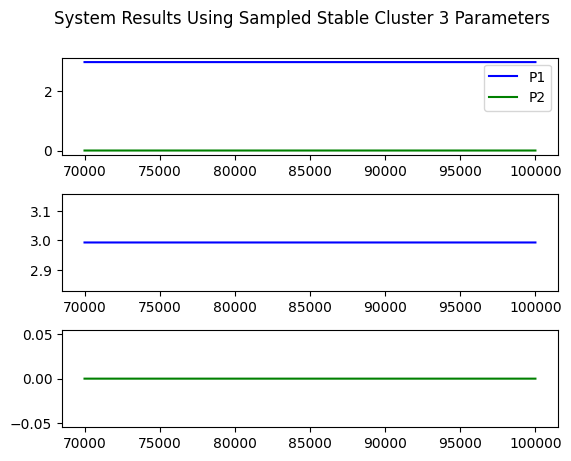

In [ ]:
# Plots the graph for figure 4
fig, (ax1, ax2, ax3) = plt.subplots(3)
plt.suptitle("System Results Using Sampled Stable Cluster 3 Parameters")
ax1.plot(t[70000:], P[70000:,0], color='b', label="P1")
ax1.plot(t[70000:], P[70000:,1], color='g', label="P2")

ax2.plot(t[70000:], P[70000:,0], color='b', label="P1")
ax3.plot(t[70000:], P[70000:,1], color='g', label="P2")

ax1.legend()

plt.subplots_adjust(hspace=0.4)

plt.show()

In [ ]:
bounds = np.array([
    [0.0, 0.931314],   # a
    [0.0, 0.017008],   # b
    [0.0, 0.254914],   # c
    [0.0, 0.964735],   # d
    [0.0, 0.250212],   # e
    [0.0, 0.054510],   # f
    [-1.0, 1.0],   # alpha
])


boxes, X_high, p_high, X_pool, p_class = likely_class_boxes_clustered(
      model=modelB,
      target_class=0,
      bounds=bounds,
      p_threshold=0.9,
      n_power=18,
      n_clusters=6,
      q_low=0.05,
      q_high=0.95,
      min_cluster_size=30,
      seed=None
)
param_names = ["a", "b", "c", "d", "e", "f", "alpha"]

for item in boxes:
  print()
  print(f"Cluster {item['cluster']}")
  print(f"n_points: {item['n_points']}")
  print(f"mean P: {item['mean_probability']:.4f}")
  for name, (lo, hi) in zip(param_names, item["box"]):
    print(f"{name}: [{lo:.4f}, {hi:.4f}]")


Cluster 0
n_points: 203
mean P: 0.9120
a: [0.2554, 0.5525]
b: [0.0022, 0.0109]
c: [0.0022, 0.1013]
d: [0.4957, 0.8542]
e: [0.1659, 0.2363]
f: [0.0041, 0.0394]
alpha: [0.5017, 0.7670]

Cluster 1
n_points: 333
mean P: 0.9147
a: [0.5865, 0.9077]
b: [0.0023, 0.0110]
c: [0.0081, 0.0988]
d: [0.3676, 0.6262]
e: [0.1621, 0.2419]
f: [0.0045, 0.0434]
alpha: [0.4542, 0.8114]

Cluster 2
n_points: 269
mean P: 0.9155
a: [0.7110, 0.9073]
b: [0.0021, 0.0112]
c: [0.0093, 0.1781]
d: [0.6352, 0.9306]
e: [0.1259, 0.2398]
f: [0.0026, 0.0377]
alpha: [0.6762, 0.8968]

Cluster 3
n_points: 238
mean P: 0.9165
a: [0.4305, 0.6835]
b: [0.0019, 0.0117]
c: [0.0067, 0.1455]
d: [0.6623, 0.9360]
e: [0.1584, 0.2411]
f: [0.0040, 0.0378]
alpha: [0.6488, 0.8782]

Cluster 4
n_points: 222
mean P: 0.9163
a: [0.5705, 0.8891]
b: [0.0023, 0.0105]
c: [0.0076, 0.1044]
d: [0.6699, 0.9327]
e: [0.1389, 0.2423]
f: [0.0037, 0.0394]
alpha: [0.4388, 0.6516]

Cluster 5
n_points: 361
mean P: 0.9132
a: [0.4910, 0.8951]
b: [0.0025, 0.0109]


In [ ]:
cluster_id = 3

cluster_item = next(
    item for item in boxes
    if item["cluster"] == cluster_id
)

a, b, c, d, e, f, alpha = sample_from_cluster_box(
    model=modelB,
    cluster_item=cluster_item,
    target_class=0,
    p_threshold=0.9,
    seed=42
)

print(a, b, c, d, e, f, alpha)

0.5424173317429366 0.008446763325462361 0.061061727463333014 0.9325275097766248 0.21497714723600622 0.037320811924222236 0.8596770935734757


In [ ]:
"""
Parameters and initial values.
"""
p0 = np.array([3, 10])
r0 = np.array([5, 20])
n = 100000
params = [a, b, c, d, e, f]

In [ ]:
P, R, t = combinedModel(p0, r0, alpha, params, n)

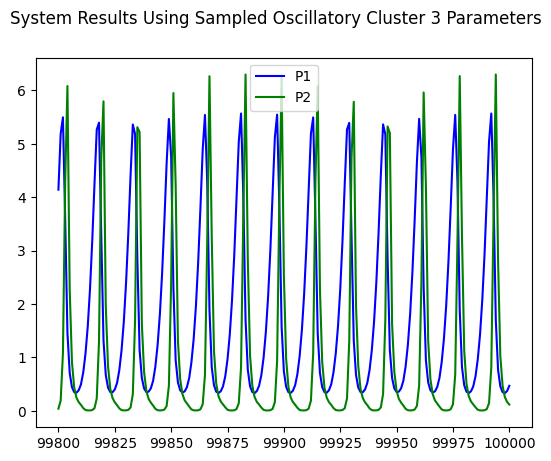

In [ ]:
# Plots the graph for figure 4
fig, ax1 = plt.subplots(1)
plt.suptitle("System Results Using Sampled Oscillatory Cluster 3 Parameters")
ax1.plot(t[99800:], P[99800:,0], color='b', label="P1")
ax1.plot(t[99800:], P[99800:,1], color='g', label="P2")

#ax2.plot(t[70000:], P[70000:,0], color='b', label="P1")

#ax3.plot(t[70000:], P[70000:,1], color='g', label="P2")

ax1.legend()

plt.subplots_adjust(hspace=0.4)

plt.show()

# Model C: transitions as $\alpha$ varies

Models A and B each label one point $\theta$. The change between stable and oscillatory dynamics is instead a location in $\alpha$, for fixed $(a,b,c,d,e,f)$. `alpha_crossings.json` stores that base vector in $X$ and the detected crossing values of $\alpha$ in $y$.

Each base vector is turned into labelled examples on $\alpha\in[-1,1]$, with spacing $\Delta\alpha=0.01$. Around each crossing $\alpha_c$ the transition interval is

$
\bigl(\max(-1,\alpha_c-\Delta\alpha),\,\min(1,\alpha_c)\bigr).
$

One of those intervals is chosen at random and a positive example, labelled $1$, is drawn uniformly inside it. A negative example, labelled $0$, is drawn from the $\alpha$ grid outside every transition interval of that base vector. Both rows carry the same $(a,b,c,d,e,f)$ and the same group id. If a base vector has no crossing, it contributes only a negative; if the grid is entirely covered by transition intervals, it contributes only a positive.

`GroupShuffleSplit` holds out 25% of the groups. Every $\alpha$ attached to one base vector stays entirely in training or entirely in test, so a test $\alpha$ is scored without the model having seen the neighboring values from the same $(a,b,c,d,e,f)$.

The label is

$
y_C =
\begin{cases}
1, & \alpha\text{ lies in a detected transition interval}\\
0, & \alpha\text{ lies outside those intervals}
\end{cases}
$

and Model C estimates $P_C(y=1\mid a,b,c,d,e,f,\alpha)$.

In [ ]:
dataC = pd.read_json("alpha_crossings.json")
X_C = np.asarray(list(dataC["X"]), dtype=float)
y_C = np.asarray(dataC["y"])
n_C = len(X_C)

In [ ]:
def build_alphas(d_alpha, start, end):
    if start > end:
        start, end = end, start

    alphas = np.arange(start, end + d_alpha, d_alpha)
    return alphas

In [ ]:
d_alpha = 0.01
alphas = build_alphas(d_alpha, -1, 1)
alphas = [round(float(a), 2) for a in alphas]
len_a = len(alphas)

In [ ]:
Xn = []
yn = []
groups = []

In [ ]:
rng = np.random.default_rng(seed=0)

for j in range(n_C):
  x = np.asarray(X_C[j], dtype=float)
  crossings = [float(v) for v in y_C[j]]

  intervals = [
      (max(-1.0, a - d_alpha), min(1.0, a))
      for a in crossings
  ]

  if len(intervals) > 0:
      lo, hi = intervals[rng.integers(len(intervals))]
      alpha_pos = float(rng.uniform(lo, hi))
      Xn.append(np.r_[x, alpha_pos])
      yn.append(1)
      groups.append(j)

  valid_neg_alphas = [
      float(a) for a in alphas
      if not any(lo <= a <= hi for lo, hi in intervals)

  ]

  if len(valid_neg_alphas) > 0:
      alpha_neg = float(rng.choice(valid_neg_alphas))
      Xn.append(np.r_[x, alpha_neg])
      yn.append(0)
      groups.append(j)

In [ ]:
Xn = np.asarray(Xn, dtype=float)
yn = np.asarray(yn, dtype=int)
groups = np.asarray(groups, dtype=int)

print(Xn.shape)
print(np.unique(yn, return_counts=True))

(1766, 7)
(array([0, 1]), array([1024,  742]))


### Dataset generation and validation

The dataset was initially generated using a threshold-crossing-or-contact product criterion. We subsequently checked this criterion against an explicit threshold-label-change rule across all adjacent valid pairs in the parameter scans used to construct the dataset. Both rules identified identical transition intervals and produced identical labels for all retained examples. We therefore use the label-change formulation presented here; no relabelling or retraining was required.

In [ ]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=0

)

train_idx, test_idx = next(splitter.split(Xn, yn, groups=groups))
X_train = Xn[train_idx]
X_test = Xn[test_idx]
y_train = yn[train_idx]
y_test = yn[test_idx]

# The support-vector classifier

Model C is a radial-basis support vector machine in a pipeline with `StandardScaler`. Scaling comes first because the RBF kernel depends on Euclidean distance, and $\alpha\in[-1,1]$ would otherwise sit on a different scale from $(a,b,c,d,e,f)$.

The `SVC` uses an RBF kernel, penalty $C=10$, `gamma="scale"`, `class_weight="balanced"`, and `probability=True`. The RBF kernel can place a thin set along $\alpha$, which a linear decision in the seven coordinates would not match. $C$ sets the cost of points that fall on the wrong side of the margin. `gamma="scale"` sets the kernel width from the variance of the features. Class weights keep the fit from ignoring the transition label when the two classes are uneven. `probability=True` runs Platt scaling so the plots and the later threshold can use $P_C(y=1\mid\theta)$ rather than only the signed decision value.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

model_svc = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf",
        C=10,
        gamma="scale",
        class_weight="balanced",
        probability=True,
        random_state=0
    )
)

model_svc.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc',
                 SVC(C=10, class_weight='balanced', probability=True,
                     random_state=0))])

### Bifurcation classifier evaluation

The classifier was evaluated using the following labels:

- $y=0$: **no detected bifurcation**
- $y=1$: **bifurcation-region sample**

The confusion matrix shows approximately:

| Actual class | Predicted $0$ | Predicted $1$ |
|---|---:|---:|
| No bifurcation ($0$) | $\approx170$ | $89$ |
| Bifurcation ($1$) | $37$ | $\approx150$ |

The overall classification accuracy is approximately

$$
0.71.
$$

For the **non-bifurcation class** ($y=0$), the classifier achieves:

- Precision: $0.82$
- Recall: $0.65$
- F1-score: $0.73$

The relatively high precision means that when the model predicts that a point is outside the bifurcation region, this prediction is usually correct. However, the recall of $0.65$ shows that a substantial proportion of true non-bifurcation points are instead classified as bifurcation candidates. This is visible in the $89$ false-positive predictions in the confusion matrix.

For the **bifurcation class** ($y=1$), the classifier achieves:

- Precision: $0.62$
- Recall: $0.80$
- F1-score: $0.70$

The most important feature of the bifurcation class is its relatively high recall. Approximately $80\%$ of the true bifurcation-region samples are identified, while only $37$ are missed and classified as non-bifurcation points. The lower precision of $0.62$ means that the predicted bifurcation region also contains a significant number of false positives.

This produces a useful asymmetry for the intended application. If the purpose of the classifier is to identify **candidate parameter regions in which bifurcations may occur**, relatively high recall is preferable to very high precision: it is generally better to retain additional false-positive candidates for subsequent simulation than to exclude true bifurcation regions entirely.

The macro-averaged scores are:

$$
\text{Precision}_{\mathrm{macro}} = 0.72,
$$

$$
\text{Recall}_{\mathrm{macro}} = 0.73,
$$

$$
F1_{\mathrm{macro}} = 0.71.
$$

The weighted F1-score is approximately $0.72$, indicating reasonably balanced performance across the two classes.

Overall, the classifier provides a useful reduction of the parameter space but should not be interpreted as an exact detector of the bifurcation boundary. Its main value is as a **screening model**: parameter combinations assigned a high probability of $y=1$ can be prioritised for more expensive direct simulation and bifurcation verification.

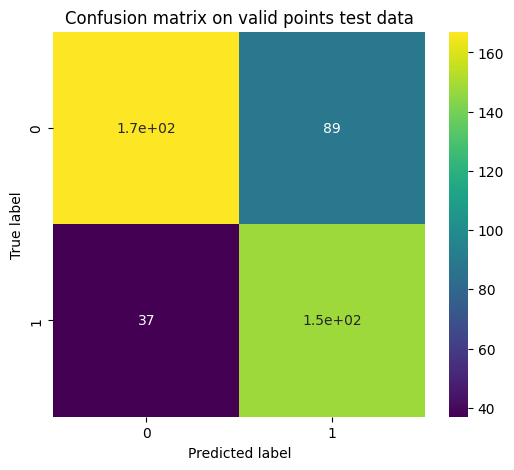

In [ ]:
y_pred = model_svc.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
plt.title("Confusion matrix on valid points test data")
sn.heatmap(cm, cmap="viridis", annot=True)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()

<Axes: title={'center': 'Classification report on valid points test data'}>

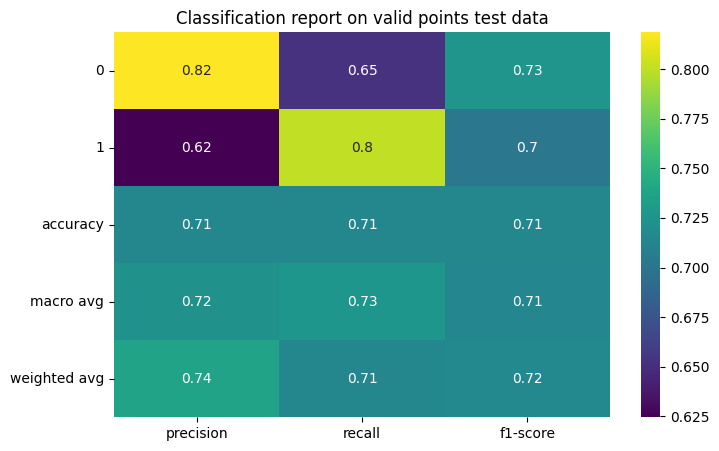

In [ ]:
cr = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
df_cr = pd.DataFrame(cr).T
metrics = ["precision", "recall", "f1-score"]
plt.figure(figsize=(8, 5))
plt.title("Classification report on valid points test data")
sn.heatmap(df_cr[metrics], cmap="viridis", annot=True)

### Probability calibration of the bifurcation classifier

The calibration curves compare the classifier's predicted probabilities with the empirical frequency of each class.

For a perfectly calibrated classifier, predictions with probability $p$ should correspond to an empirical class frequency of approximately $p$. The dashed diagonal therefore represents perfect calibration.

The classes are:

- $y=0$: **no detected bifurcation**
- $y=1$: **bifurcation-region sample**

#### Calibration for class $0$

The calibration curve for the non-bifurcation class follows the diagonal reasonably well overall, although some deviations are visible in the intermediate probability range.

For predicted probabilities around

$$
P(y=0)\approx0.35-0.65,
$$

the empirical fraction fluctuates above and below the ideal calibration line. This indicates that probabilities in this range should not be interpreted as exact estimates of the probability of belonging to the non-bifurcation class.

At higher predicted probabilities, approximately

$$
P(y=0)>0.7,
$$

the empirical non-bifurcation frequency is very high and generally lies above the diagonal. Thus, high-confidence predictions of class $0$ appear reliable and, if anything, somewhat conservative: points assigned a high probability of being non-bifurcation points are very frequently observed to be non-bifurcation points.

#### Calibration for class $1$

The bifurcation class shows somewhat greater calibration error.

At low predicted probabilities,

$$
P(y=1)\lesssim0.3,
$$

the empirical frequency of bifurcation samples is lower than the predicted probability. In this region the classifier tends to **overestimate** the probability of class $1$.

In the intermediate probability range, approximately

$$
P(y=1)\approx0.4-0.7,
$$

the curve moves both above and below the perfect-calibration line. For example, some probability bins around $0.5-0.6$ contain substantially more bifurcation samples than predicted, whereas other nearby bins are close to the ideal line.

The class-$1$ probabilities therefore contain useful information about relative confidence, but they are not perfectly calibrated as literal probabilities.

#### Interpretation

The calibration results support using the classifier primarily as a **parameter-space screening model** rather than treating its output probabilities as exact probabilities of bifurcation.

In particular, the model can be used to rank candidate parameter vectors according to

$$
P(y=1\mid a,b,c,d,e,f,\alpha),
$$

and high-probability regions can then be prioritised for direct numerical simulation and bifurcation verification.

This is consistent with the classification results: the objective is not necessarily to determine the bifurcation boundary exactly from the classifier alone, but to efficiently reduce the parameter space to regions in which bifurcations are more likely to occur.

If the predicted probabilities are later used directly as probabilistic constraints or optimisation penalties, additional probability calibration on an independent validation set would be appropriate.

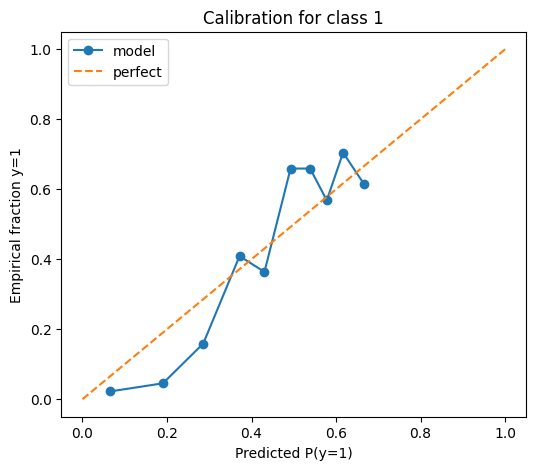

In [ ]:
probs = model_svc.predict_proba(X_test)

target_class = 1
idx = np.where(model_svc.classes_ == target_class)[0][0]

p_class = probs[:, idx]

plot_calibration(
    y_true=y_test,
    p_class=p_class,
    target_class=target_class,
    n_bins=10
)

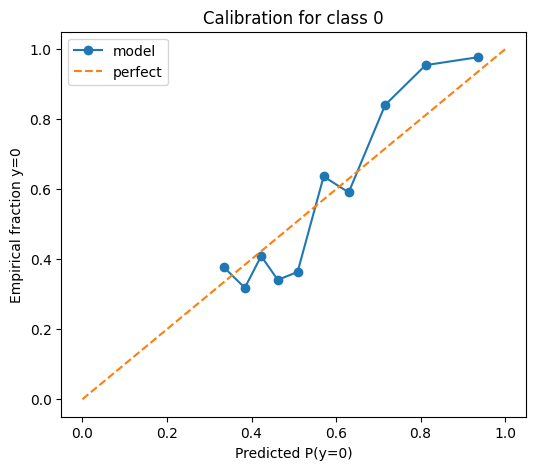

In [ ]:
target_class = 0
idx = np.where(model_svc.classes_ == target_class)[0][0]

p_class = probs[:, idx]

plot_calibration(
    y_true=y_test,
    p_class=p_class,
    target_class=target_class,
    n_bins=10
)

In [ ]:
def plot_svc_alpha_profile(model, abcdef, crossings=None, d_alpha=None, n_alpha=400):

    abcdef = np.asarray(abcdef, dtype=float)
    alpha_grid = np.linspace(-1, 1, n_alpha)
    X_plot = np.column_stack([np.tile(abcdef, (n_alpha, 1)), alpha_grid])

    if hasattr(model, "predict_proba"):
        score = model.predict_proba(X_plot)[:, 1]
        ylabel = "Predicted P(transition)"

    else:
        score = model.decision_function(X_plot)
        ylabel = "SVC decision score"

    plt.figure(figsize=(9, 4))
    plt.plot(alpha_grid, score, label="SVC score")

    if crossings is not None and d_alpha is not None:

        for c in crossings:

            lo = max(-1, c - d_alpha)
            hi = min(1, c)
            plt.axvspan(lo, hi, alpha=0.2, label="Detected transition interval")

    plt.axhline(0.5, linestyle="--", linewidth=1, label="0.5 threshold")
    plt.xlabel("alpha")
    plt.ylabel(ylabel)
    plt.title("SVC transition score as alpha varies for fixed (a,b,c,d,e,f)")
    plt.legend()
    plt.show()

### SVC transition profile as $\alpha$ varies

This plot shows how the trained transition classifier responds when the six Lotka--Volterra parameters

$$
(a,b,c,d,e,f)
$$

are held fixed and only the interaction parameter $\alpha$ is varied continuously over

$$
-1 \leq \alpha \leq 1.
$$

For each value of $\alpha$, the corresponding seven-dimensional parameter vector

$$
(a,b,c,d,e,f,\alpha)
$$

is passed to the classifier. Since the fitted SVC supports `predict_proba`, the plotted quantity is

$$
P(y=1\mid a,b,c,d,e,f,\alpha),
$$

where $y=1$ denotes a parameter combination classified as belonging to a **transition / bifurcation region**.

The dashed horizontal line at

$$
P(y=1)=0.5
$$

shows the default classification threshold. Values above this line are classified as transition-region points, while values below it are classified as non-transition points.

For this particular fixed parameter set, the predicted transition probability is relatively low for strongly negative $\alpha$. It decreases initially to approximately $0.25$, before increasing as $\alpha$ approaches zero. The probability crosses the $0.5$ classification threshold at approximately

$$
\alpha \approx 0.05.
$$

It then continues increasing and reaches a maximum of approximately

$$
P(y=1)\approx0.61
$$

around

$$
\alpha\approx0.4.
$$

The predicted probability subsequently decreases and crosses below the $0.5$ threshold again at approximately

$$
\alpha\approx0.65.
$$

The classifier therefore identifies approximately

$$
0.05 \lesssim \alpha \lesssim 0.65
$$

as a candidate transition region for this particular choice of $(a,b,c,d,e,f)$.

An important point is that the two $0.5$ crossings in this plot are **classifier decision boundaries**, not necessarily two actual dynamical bifurcation points. The classifier was trained to identify neighbourhoods associated with detected transitions, so a high value of $P(y=1)$ indicates that the parameter vector resembles the transition-region samples in the training data. The exact bifurcation value must still be established using the underlying trajectory-based bifurcation test.

The smooth variation of the score is nevertheless useful because it provides a one-dimensional slice through the learned seven-dimensional transition region. Rather than returning only a binary prediction, the model shows how strongly the fixed dynamical system is associated with the learned bifurcation region as $\alpha$ changes. This can therefore be used to identify restricted intervals of $\alpha$ that should be prioritised for more expensive direct simulation and bifurcation verification.

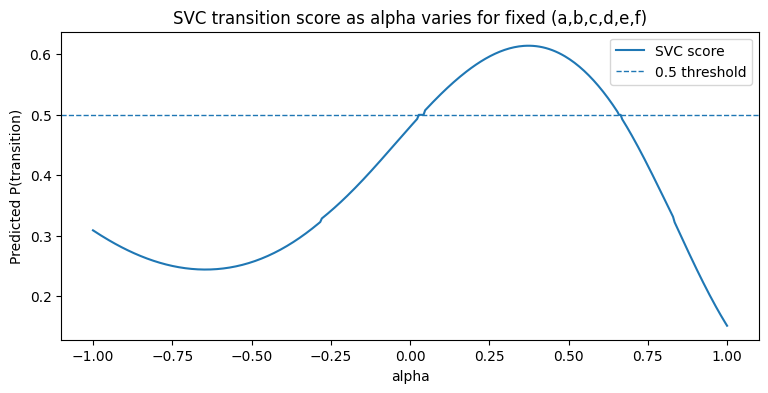

In [ ]:
abcdef_mean = X_train[:, :6].mean(axis=0)

plot_svc_alpha_profile(
    model_svc,
    abcdef=abcdef_mean,
    crossings=None,
    d_alpha=d_alpha
)

### Pairwise slices of the learned transition region

The figure visualises the transition classifier over all pairwise combinations of the seven parameters

$$
(a,b,c,d,e,f,\alpha).
$$

Since there are seven parameters, there are

$$
\binom{7}{2}=21
$$

distinct parameter pairs, corresponding to the 21 panels shown.

For each panel, two parameters are varied over their observed ranges while the remaining five parameters are held fixed at a reference value taken from `X_ref` (the mean in the plot shown). For example, in the $a$ vs $\alpha$ panel, the classifier is evaluated at points of the form

$$
(a,\bar b,\bar c,\bar d,\bar e,\bar f,\alpha),
$$

where only $a$ and $\alpha$ vary.

A $100\times100$ grid is evaluated for each pair. Because the SVC supports `predict_proba`, the colour at each point represents

$$
P(y=1\mid a,b,c,d,e,f,\alpha),
$$

where $y=1$ denotes a **transition / bifurcation-region sample**.

- Darker regions correspond to low predicted transition probability.
- Lighter regions correspond to high predicted transition probability.
- The contour line marks

$$
P(y=1)=0.5,
$$

and therefore represents the classifier's decision boundary in that particular two-dimensional slice.

#### Interpretation of the results

The plots show that the learned transition region is strongly **nonlinear**. Most of the $0.5$ contours are curved rather than straight, indicating that the effect of one parameter depends on the value of another parameter. The transition region therefore cannot be described well using independent thresholds such as $a>a_0$ or $d<d_0$.

The plots involving $\alpha$ are particularly informative. In the $a$--$\alpha$, $b$--$\alpha$, $c$--$\alpha$, $d$--$\alpha$, $e$--$\alpha$, and $f$--$\alpha$ slices, the classifier generally identifies an intermediate band of $\alpha$ values with elevated transition probability. The position and width of this band change as the other parameter varies.

This suggests an interaction of the form

$$
\text{transition likelihood}
=
g(a,b,c,d,e,f,\alpha),
$$

rather than the transition being determined by $\alpha$ alone. In particular, a value of $\alpha$ associated with a transition for one set of Lotka--Volterra parameters may not correspond to a transition for another set.

Several of the non-$\alpha$ plots also show pronounced curved boundaries. For example, the $a$--$d$, $c$--$d$, $c$--$e$, and $d$--$e$ slices show substantial changes in predicted probability across different combinations of the two parameters. This is further evidence that the bifurcation region depends on interactions between the underlying system parameters.

Parameters such as $b$ and $f$ appear to produce somewhat smoother or less dramatic changes in several of these particular slices, although they can still shift the transition boundary. This should not be interpreted as evidence that they are globally unimportant: their apparent influence depends on the values at which the other five parameters have been fixed.

#### What these plots do and do not show

These figures are **conditional two-dimensional slices of a seven-dimensional learned surface**. They are not projections or averages over the other five parameters.

Consequently, a contour in one panel means:

> When the other five parameters are fixed at their reference values, the SVC predicts $P(y=1)=0.5$ along this curve.

It does **not** mean that this curve is the true bifurcation boundary for every possible choice of the remaining parameters.

Similarly, the light regions are regions that the classifier considers likely to belong to the transition class; they are not direct numerical proofs that a bifurcation occurs there. Candidate points should still be checked using the original trajectory-based bifurcation procedure.

Overall, the pairwise slices indicate that the classifier has learned a structured, nonlinear transition region with substantial interactions between parameters. The particularly strong dependence of the transition band on $\alpha$ and its interaction with parameters such as $a$, $c$, $d$, and $e$ is consistent with the idea that bifurcations occur on a complicated lower-dimensional region of the full parameter space rather than at a single universal value of $\alpha$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_svc_pairwise_slices(model, X_ref, grid_n=100, fill_method="mean", param_names=None, contour_threshold=0.5):

    X_ref = np.asarray(X_ref, dtype=float)

    if X_ref.shape[1] > 7:
        X_ref = X_ref[:, :7]

    if param_names is None:
        param_names = ["a", "b", "c", "d", "e", "f", "alpha"]

    if fill_method == "mean":
        filler = X_ref.mean(axis=0)
    else:
        filler = np.median(X_ref, axis=0)

    pairs = [(i, j) for i in range(7) for j in range(i + 1, 7)]
    nplots = len(pairs)

    nrows, ncols = 3, 7

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(4.2 * ncols, 3.8 * nrows),
        constrained_layout=True
    )

    axes = axes.ravel()
    hms = []

    for ax, (i, j) in zip(axes, pairs):
        xi = np.linspace(X_ref[:, i].min(), X_ref[:, i].max(), grid_n)
        xj = np.linspace(X_ref[:, j].min(), X_ref[:, j].max(), grid_n)

        I, J = np.meshgrid(xi, xj)

        X_grid = np.tile(filler, (I.size, 1))
        X_grid[:, i] = I.ravel()
        X_grid[:, j] = J.ravel()

        if hasattr(model, "predict_proba"):
            Z = model.predict_proba(X_grid)[:, 1].reshape(I.shape)
            label = "Predicted P(transition)"
            levels = np.linspace(0, 1, 51)
            hm = ax.contourf(I, J, Z, levels=levels)
            ax.contour(I, J, Z, levels=[contour_threshold], linewidths=2)
        else:
            Z = model.decision_function(X_grid).reshape(I.shape)
            label = "SVC decision score"
            hm = ax.contourf(I, J, Z, levels=50)
            ax.contour(I, J, Z, levels=[0], linewidths=2)

        hms.append(hm)

        ax.set_xlabel(param_names[i])
        ax.set_ylabel(param_names[j])
        ax.set_title(f"{param_names[i]} vs {param_names[j]}")

    for ax in axes[nplots:]:
        ax.axis("off")

    cbar = fig.colorbar(hms[-1], ax=axes[:nplots], fraction=0.02, pad=0.02)
    cbar.set_label(label)

    fig.suptitle(
        f"SVC pairwise transition surface slices — others fixed at {fill_method}",
        y=1.02
    )

    plt.show()

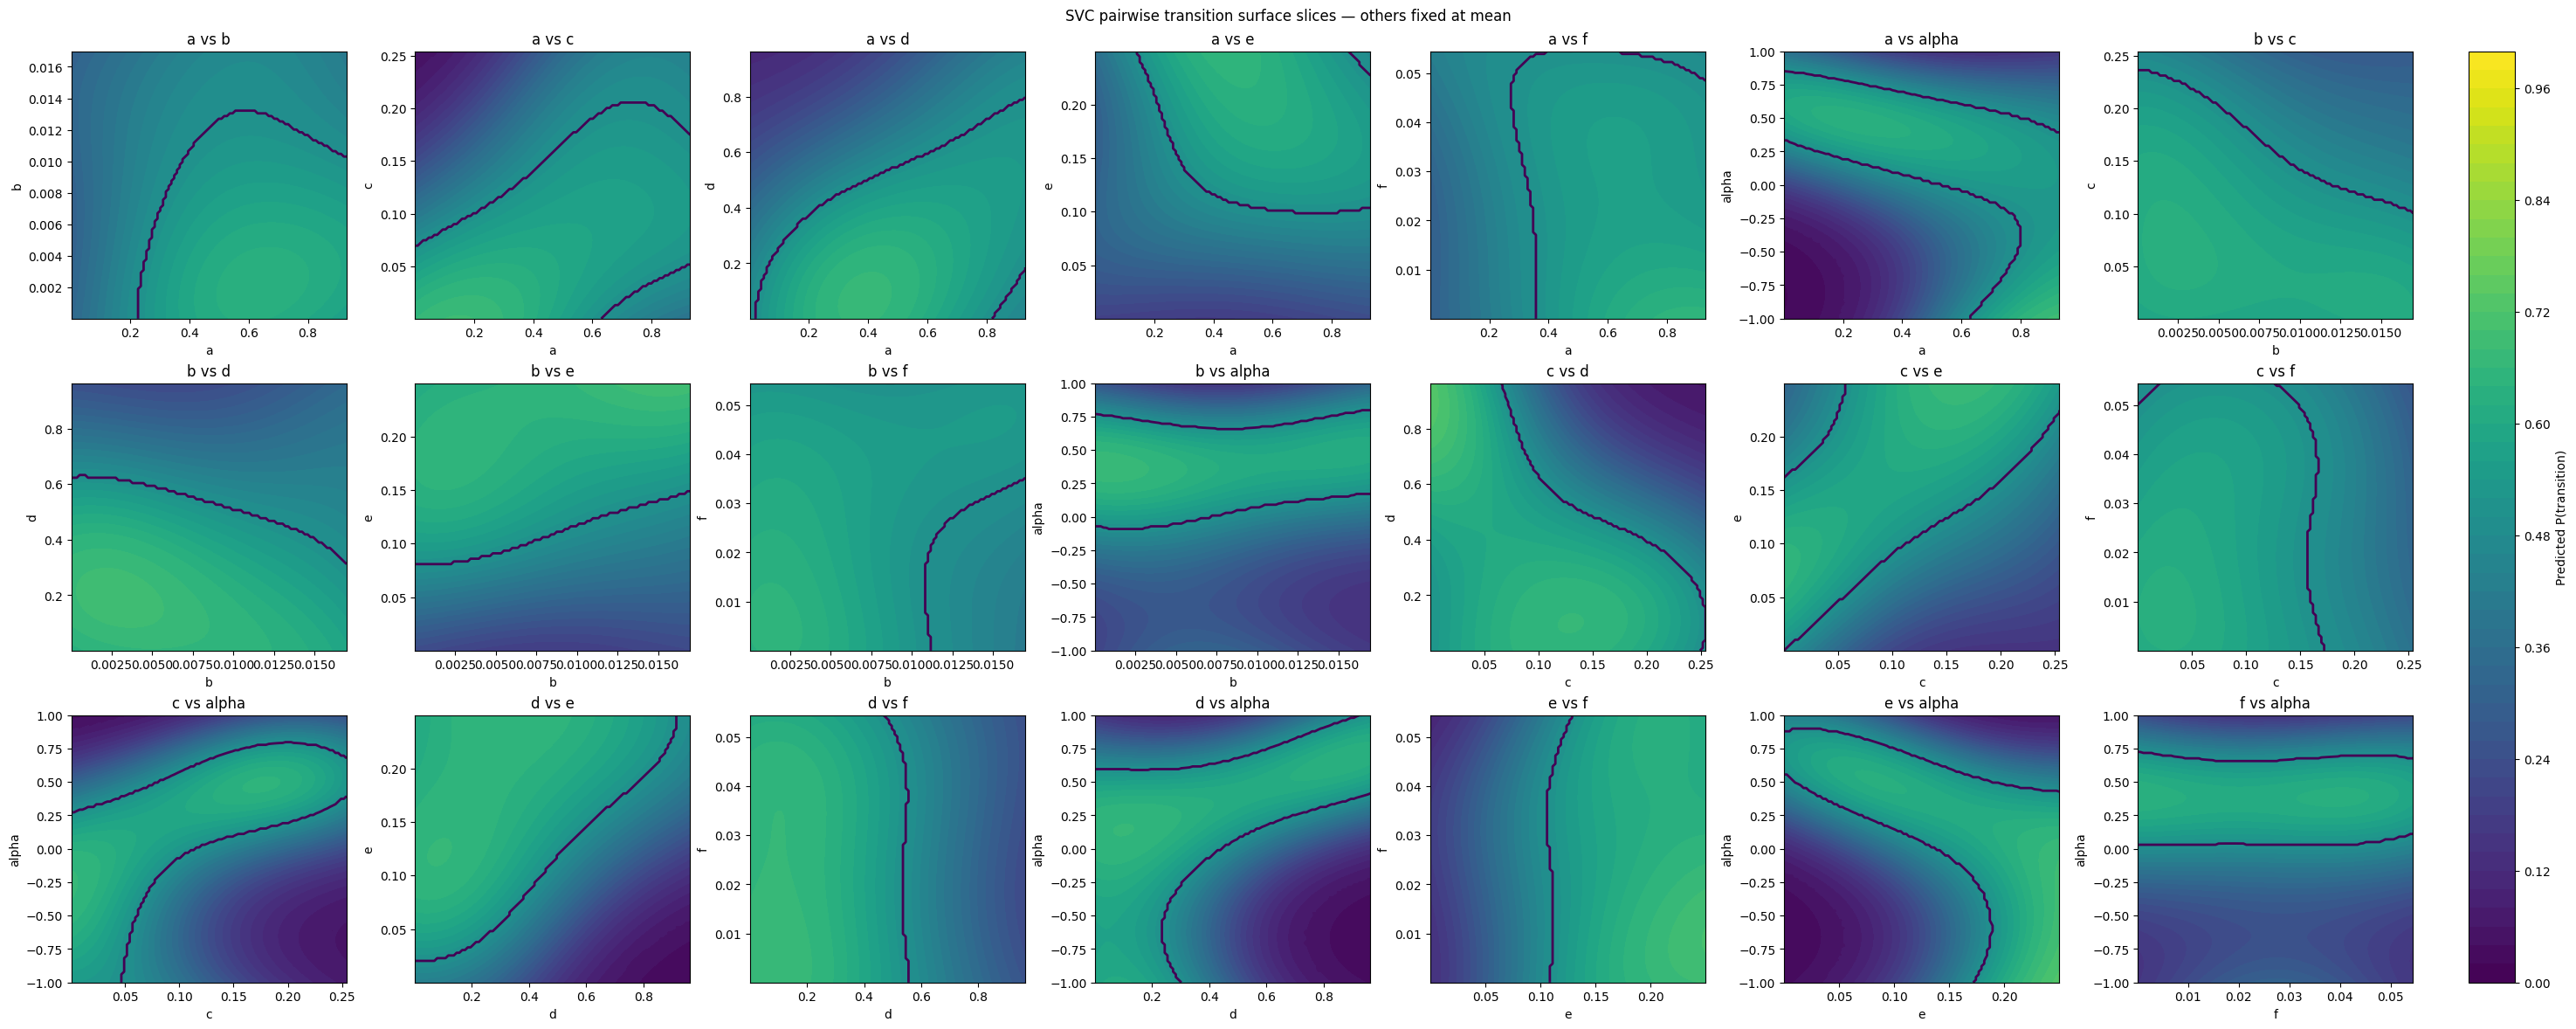

In [ ]:
plot_svc_pairwise_slices(
    model_svc,
    X_train,
    grid_n=100,
    fill_method="mean",
    contour_threshold=0.5
)

In [ ]:
def plot_svc_pca_slice(model, X_ref, y_ref=None, grid_n=150, contour_threshold=0.5, show_points=True):

    X_ref = np.asarray(X_ref, dtype=float)

    if X_ref.shape[1] > 7:
        X_ref = X_ref[:, :7]

    if y_ref is not None:
        y_ref = np.asarray(y_ref)

    if hasattr(model, "named_steps") and "standardscaler" in model.named_steps:
        scaler = model.named_steps["standardscaler"]
        X_scaled = scaler.transform(X_ref)
    else:
        scaler = None
        X_scaled = X_ref

    pca = PCA(n_components=2)
    Z = pca.fit_transform(X_scaled)

    z1_min, z1_max = Z[:, 0].min(), Z[:, 0].max()
    z2_min, z2_max = Z[:, 1].min(), Z[:, 1].max()

    pad1 = 0.05 * (z1_max - z1_min + 1e-12)
    pad2 = 0.05 * (z2_max - z2_min + 1e-12)

    pc1 = np.linspace(z1_min - pad1, z1_max + pad1, grid_n)
    pc2 = np.linspace(z2_min - pad2, z2_max + pad2, grid_n)

    PC1, PC2 = np.meshgrid(pc1, pc2)
    Z_grid = np.column_stack([PC1.ravel(), PC2.ravel()])

    X_grid_scaled = pca.inverse_transform(Z_grid)

    if scaler is not None:
        X_grid = scaler.inverse_transform(X_grid_scaled)
    else:
        X_grid = X_grid_scaled

    lower = X_ref.min(axis=0)
    upper = X_ref.max(axis=0)
    X_grid = np.clip(X_grid, lower, upper)

    if hasattr(model, "predict_proba"):
        score = model.predict_proba(X_grid)[:, 1]
        label = "Predicted P(transition)"
        Z_score = score.reshape(PC1.shape)

        levels = np.linspace(0, 1, 51)
        boundary_level = contour_threshold
    else:
        score = model.decision_function(X_grid)
        label = "SVC decision score"
        Z_score = score.reshape(PC1.shape)

        levels = 50
        boundary_level = 0.0

    plt.figure(figsize=(8, 6))

    hm = plt.contourf(PC1, PC2, Z_score, levels=levels)

    plt.contour(PC1, PC2, Z_score, levels=[boundary_level], linewidths=2)

    if show_points:
        if y_ref is not None:
            plt.scatter(Z[:, 0], Z[:, 1], c=y_ref, s=18, edgecolor="k", linewidth=0.2, alpha=0.7)
        else:
            plt.scatter(Z[:, 0], Z[:, 1], s=18, edgecolor="k", linewidth=0.2, alpha=0.7)

    cbar = plt.colorbar(hm)
    cbar.set_label(label)

    explained = pca.explained_variance_ratio_

    plt.xlabel(f"PC1 ({explained[0] * 100:.1f}% variance)")
    plt.ylabel(f"PC2 ({explained[1] * 100:.1f}% variance)")
    plt.title("SVC transition surface projected into PCA space")

    plt.show()

    return pca, Z

### PCA visualisation of the learned transition surface

The classifier operates in the full seven-dimensional parameter space

$$
(a,b,c,d,e,f,\alpha),
$$

so PCA is used here only to obtain a two-dimensional visualisation of the learned transition structure.

The first two principal components explain approximately

$$
16.5\% + 15.6\% = 32.1\%
$$

of the total variance in the parameter data.

The plotted observations are the original parameter vectors projected into the $(\mathrm{PC1},\mathrm{PC2})$ plane. The two classes overlap substantially, indicating that transition and non-transition samples are not cleanly separable using only the two dominant linear directions of variation.

The coloured background represents the SVC prediction

$$
P(y=1),
$$

where $y=1$ denotes a transition / bifurcation-region sample. The contour line corresponds to

$$
P(y=1)=0.5,
$$

and therefore shows the classifier's decision boundary in this PCA representation.

The surface is clearly nonlinear, with curved and disconnected regions of relatively high and low predicted transition probability. This is consistent with the pairwise parameter plots and suggests that the transition region has a complex geometry in the original parameter space.

An important limitation is that this is not a complete projection of the seven-dimensional decision surface. For each point in the PC1--PC2 grid, the code performs an inverse PCA transformation using only the first two components. The remaining principal-component coordinates are effectively fixed at their mean values before the reconstructed parameter vector is passed to the classifier.

Therefore, the background should be interpreted as a **two-dimensional PCA slice through the learned transition surface**, rather than as the average transition probability over all possible parameter vectors corresponding to a given $(\mathrm{PC1},\mathrm{PC2})$ position.

This also explains why individual labelled observations may sometimes appear inconsistent with the background underneath them: the original observations contain information in all seven dimensions, whereas the background is reconstructed using only the first two principal components.

Overall, the plot supports the conclusion that bifurcation-region classification depends on higher-dimensional and nonlinear interactions between the parameters. The PCA representation is useful for visualising the broad structure of the learned surface, but candidate bifurcation regions should still be identified using the full seven-dimensional classifier and verified through direct simulation.

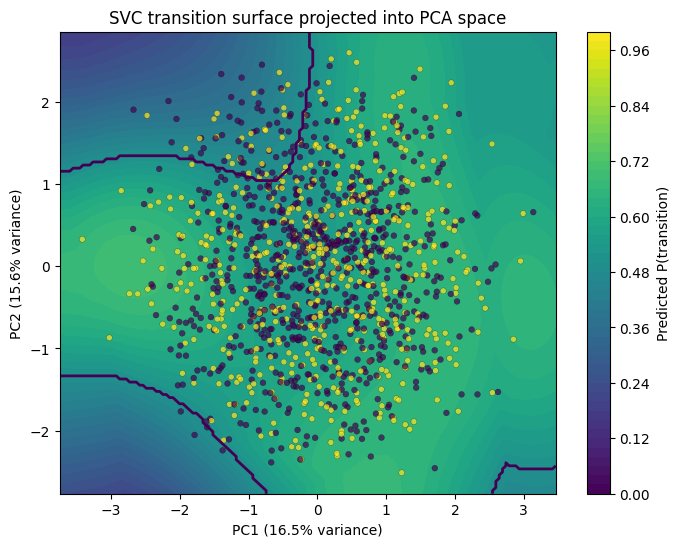

In [ ]:
pca, Z = plot_svc_pca_slice(model_svc,
    X_train,
    y_ref=y_train,
    grid_n=150,
    contour_threshold=0.5,
    show_points=True
)

In [ ]:
bounds = np.array([
    [0.0, 0.931314],   # a
    [0.0, 0.017008],   # b
    [0.0, 0.254914],   # c
    [0.0, 0.964735],   # d
    [0.0, 0.250212],   # e
    [0.0, 0.054510],   # f
    [-1.0, 1.0],   # alpha
])

fixed = {
         0: 0.25, #a
         5: 0.01  #f
        }


boxes, X_high, p_high, X_pool, p_class = likely_class_boxes_clustered(model=model_svc,
                                                                      target_class=1,
                                                                      bounds=bounds,
                                                                      fixed=fixed,
                                                                      p_threshold=0.70,
                                                                      n_power=18,
                                                                      n_clusters=1,
                                                                      q_low=0.05,
                                                                      q_high=0.95,
                                                                      min_cluster_size=20,
                                                                      seed=None)
param_names = ["a", "b", "c", "d", "e", "f", "alpha"]

In [ ]:
for item in boxes:
  print()
  print(f"Cluster {item['cluster']}")
  print(f"n_points: {item['n_points']}")
  print(f"mean P: {item['mean_probability']:.4f}")
  for name, (lo, hi) in zip(param_names, item["box"]):
    print(f"{name}: [{lo:.4f}, {hi:.4f}]")


Cluster 0
n_points: 701
mean P: 0.7153
a: [0.2500, 0.2500]
b: [0.0015, 0.0167]
c: [0.0036, 0.1504]
d: [0.0176, 0.7918]
e: [0.0777, 0.2480]
f: [0.0100, 0.0100]
alpha: [0.0395, 0.4730]


### Cluster 0

| Quantity | Value |
|---|---:|
| Number of points | 701 |
| Mean predicted probability | 0.7153 |
| $a$ | $[0.2500,\ 0.2500]$ |
| $b$ | $[0.0015,\ 0.0167]$ |
| $c$ | $[0.0036,\ 0.1504]$ |
| $d$ | $[0.0176,\ 0.7918]$ |
| $e$ | $[0.0777,\ 0.2480]$ |
| $f$ | $[0.0100,\ 0.0100]$ |
| $\alpha$ | $[0.0395,\ 0.4730]$ |